# 0a. Calculus and Vector Fields with NumPy & PyTorch

This notebook covers the calculus you need before diving into diffusion models. We'll build intuition for:

- **Derivatives**: numerical finite differences vs. PyTorch autograd
- **Gradients**: of scalar fields in 2D, with visualization
- **How autograd works**: vector–Jacobian products, and why a gradient costs about one extra pass
- **Vector fields**: definition, visualization, and physical intuition
- **Divergence**: measuring "source" vs. "sink" behavior
- **Curl and conservative fields**: rotation in 2D/3D, and the general $n$-dimensional test (a symmetric Jacobian)
- **Jacobians**: derivatives of vector-valued functions, change of variables
- **Instantaneous change of variables**: how a flow changes log-density, and the Hutchinson trace trick
- **Integration**: numerical quadrature and Monte Carlo methods
- **ODE solving**: Euler, RK4, and following vector fields (used directly in flow matching)
- **A first look at flow matching**: why straight training paths give *curved* sampling paths

Everything is implemented from scratch in NumPy and PyTorch so you can see exactly what's happening.

**Reading order:** 0a → 0b → 0c → 1 → 2 → 3 → 3b → 4 → 5 → 6 → 7. The companion documents THEORY.md (derivations) and PHYSICS.md (physical analogies) follow the same order.

In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 12

---
## 1. Derivatives: Finite Differences vs. Autograd

The derivative of $f(x)$ at a point measures its instantaneous rate of change:

$$f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}$$

We can approximate this numerically with **finite differences**, or compute it exactly with **automatic differentiation** (autograd). Let's compare both approaches.

In [2]:
# Define a function and its known analytical derivative
def f(x):
    """f(x) = x^3 - 2x^2 + x"""
    return x**3 - 2*x**2 + x

def f_prime_analytical(x):
    """f'(x) = 3x^2 - 4x + 1"""
    return 3*x**2 - 4*x + 1

# --- Method 1: Numerical (finite differences) ---
def numerical_derivative(func, x, h=1e-5):
    """Central difference: (f(x+h) - f(x-h)) / 2h"""
    return (func(x + h) - func(x - h)) / (2 * h)

# --- Method 2: PyTorch autograd ---
def autograd_derivative(func, x_val):
    x = torch.tensor(x_val, dtype=torch.float64, requires_grad=True)
    y = func(x)
    y.backward()
    return x.grad.item()

# Compare at several points
test_points = [-1.0, 0.0, 0.5, 1.0, 2.0, 3.0]
print(f"{'x':>6} | {'Analytical':>12} | {'Finite Diff':>12} | {'Autograd':>12} | {'FD Error':>12}")
print('-' * 70)
for x in test_points:
    exact = f_prime_analytical(x)
    fd = numerical_derivative(f, x)
    ag = autograd_derivative(f, x)
    print(f"{x:6.1f} | {exact:12.6f} | {fd:12.6f} | {ag:12.6f} | {abs(fd - exact):12.2e}")

     x |   Analytical |  Finite Diff |     Autograd |     FD Error
----------------------------------------------------------------------
  -1.0 |     8.000000 |     8.000000 |     8.000000 |     1.19e-10
   0.0 |     1.000000 |     1.000000 |     1.000000 |     1.00e-10
   0.5 |    -0.250000 |    -0.250000 |    -0.250000 |     1.01e-10
   1.0 |     0.000000 |     0.000000 |     0.000000 |     9.44e-11
   2.0 |     5.000000 |     5.000000 |     5.000000 |     1.66e-10
   3.0 |    16.000000 |    16.000000 |    16.000000 |     1.05e-10


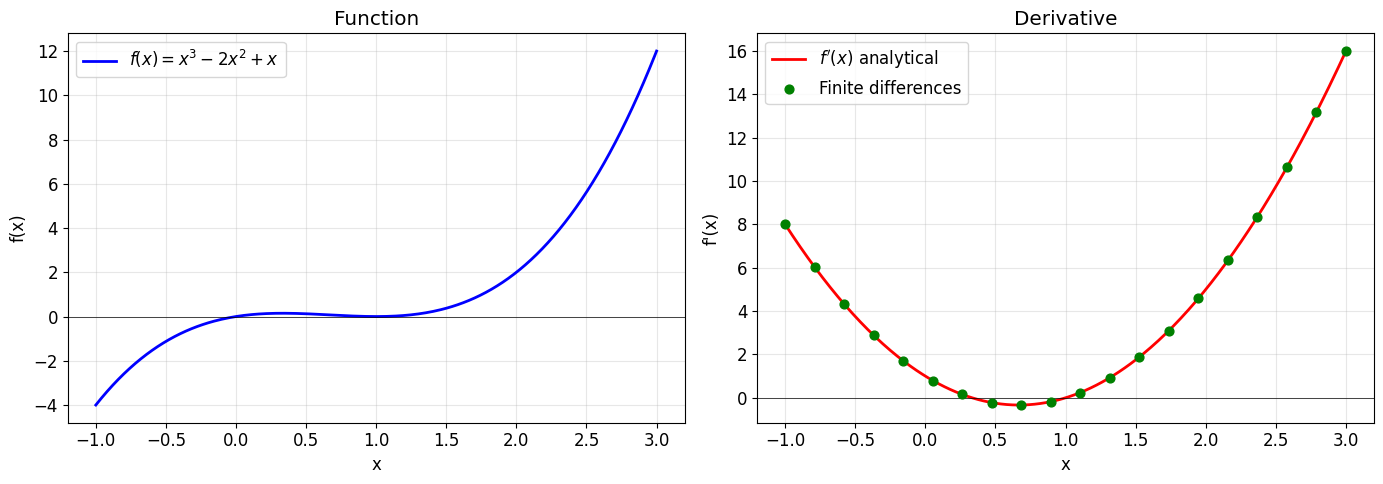

In [3]:
# Visualize the function and its derivative
x = np.linspace(-1, 3, 300)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(x, f(x), 'b-', linewidth=2, label='$f(x) = x^3 - 2x^2 + x$')
ax1.axhline(y=0, color='k', linewidth=0.5)
ax1.set_xlabel('x'); ax1.set_ylabel('f(x)')
ax1.set_title('Function'); ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(x, f_prime_analytical(x), 'r-', linewidth=2, label="$f'(x)$ analytical")
# Overlay numerical derivatives as dots
x_sparse = np.linspace(-1, 3, 20)
fd_vals = [numerical_derivative(f, xi) for xi in x_sparse]
ax2.scatter(x_sparse, fd_vals, c='green', s=40, zorder=5, label='Finite differences')
ax2.axhline(y=0, color='k', linewidth=0.5)
ax2.set_xlabel('x'); ax2.set_ylabel("f'(x)")
ax2.set_title('Derivative'); ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Effect of step size on finite difference accuracy

Smaller $h$ should give better approximations... up to a point. Too small and floating-point rounding errors dominate.

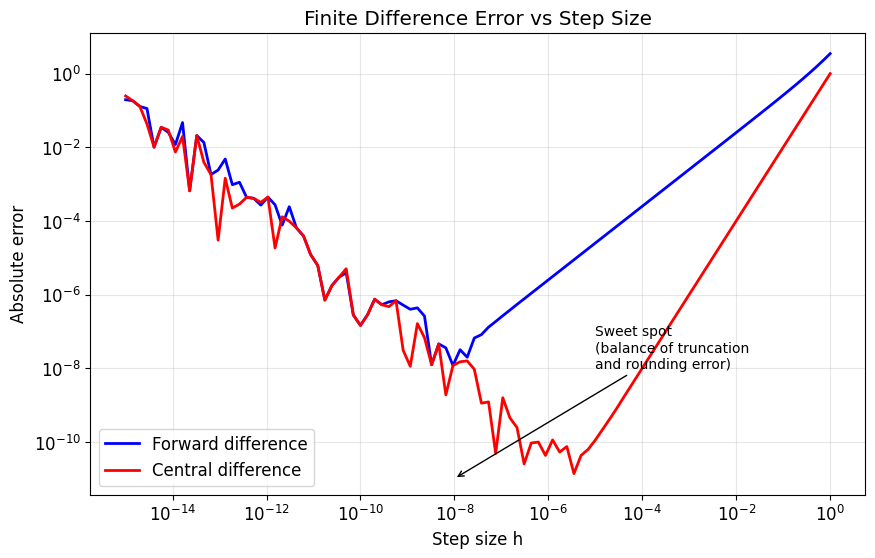

In [4]:
x0 = 1.5
exact = f_prime_analytical(x0)

h_values = np.logspace(-15, 0, 100)

# Forward difference: (f(x+h) - f(x)) / h
forward_errors = [abs((f(x0 + h) - f(x0)) / h - exact) for h in h_values]
# Central difference: (f(x+h) - f(x-h)) / 2h
central_errors = [abs((f(x0 + h) - f(x0 - h)) / (2*h) - exact) for h in h_values]

plt.figure(figsize=(10, 6))
plt.loglog(h_values, forward_errors, 'b-', label='Forward difference', linewidth=2)
plt.loglog(h_values, central_errors, 'r-', label='Central difference', linewidth=2)
plt.xlabel('Step size h')
plt.ylabel('Absolute error')
plt.title('Finite Difference Error vs Step Size')
plt.legend()
plt.grid(True, alpha=0.3, which='both')
plt.annotate('Sweet spot\n(balance of truncation\nand rounding error)',
             xy=(1e-8, 1e-11), fontsize=10,
             arrowprops=dict(arrowstyle='->', color='black'),
             xytext=(1e-5, 1e-8))
plt.show()

**Key takeaway**: Central differences converge faster (error $\sim h^2$) than forward differences (error $\sim h$). But for deep learning, autograd is exact and efficient — that's what PyTorch uses internally during backpropagation.

### Higher-order derivatives with autograd

PyTorch can compute second (and higher) derivatives by differentiating through the computation graph.

In [5]:
x = torch.tensor(2.0, requires_grad=True)
y = x**3 - 2*x**2 + x  # f(x)

# First derivative
dy_dx = torch.autograd.grad(y, x, create_graph=True)[0]
print(f"f(2)   = {y.item():.4f}")
print(f"f'(2)  = {dy_dx.item():.4f}  (analytical: {3*4 - 4*2 + 1})")

# Second derivative (differentiate through the first derivative)
d2y_dx2 = torch.autograd.grad(dy_dx, x, create_graph=True)[0]
print(f"f''(2) = {d2y_dx2.item():.4f}  (analytical: {6*2 - 4})")

# Third derivative
d3y_dx3 = torch.autograd.grad(d2y_dx2, x)[0]
print(f"f'''(2)= {d3y_dx3.item():.4f}  (analytical: 6)")

f(2)   = 2.0000
f'(2)  = 5.0000  (analytical: 5)
f''(2) = 8.0000  (analytical: 8)
f'''(2)= 6.0000  (analytical: 6)


---
## 2. Gradients of Scalar Fields

A **scalar field** assigns a number to every point in space: $f: \mathbb{R}^n \to \mathbb{R}$.

The **gradient** $\nabla f$ is a vector pointing in the direction of steepest ascent:

$$\nabla f(x, y) = \left( \frac{\partial f}{\partial x}, \frac{\partial f}{\partial y} \right)$$

This is fundamental to diffusion models: the **score function** $\nabla_x \log p(x)$ is literally the gradient of the log-probability field.

In [6]:
# Define a 2D scalar field
def scalar_field(x, y):
    """f(x,y) = sin(x) * cos(y) + 0.5*x"""
    return np.sin(x) * np.cos(y) + 0.5 * x

# Analytical gradient
def gradient_analytical(x, y):
    df_dx = np.cos(x) * np.cos(y) + 0.5
    df_dy = -np.sin(x) * np.sin(y)
    return df_dx, df_dy

# Numerical gradient using central differences
def gradient_numerical(func, x, y, h=1e-5):
    df_dx = (func(x + h, y) - func(x - h, y)) / (2 * h)
    df_dy = (func(x, y + h) - func(x, y - h)) / (2 * h)
    return df_dx, df_dy

# PyTorch autograd gradient
def gradient_autograd(x_val, y_val):
    x = torch.tensor(x_val, requires_grad=True)
    y = torch.tensor(y_val, requires_grad=True)
    f = torch.sin(x) * torch.cos(y) + 0.5 * x
    f.backward()
    return x.grad.item(), y.grad.item()

# Test at a point
x0, y0 = 1.0, 0.5
print("Gradient at (1.0, 0.5):")
print(f"  Analytical:  {gradient_analytical(x0, y0)}")
print(f"  Numerical:   {gradient_numerical(scalar_field, x0, y0)}")
print(f"  Autograd:    {gradient_autograd(x0, y0)}")

Gradient at (1.0, 0.5):
  Analytical:  (np.float64(0.9741598817790379), np.float64(-0.4034226801113349))
  Numerical:   (np.float64(0.9741598817725182), np.float64(-0.4034226801064022))
  Autograd:    (0.9741598963737488, -0.40342268347740173)


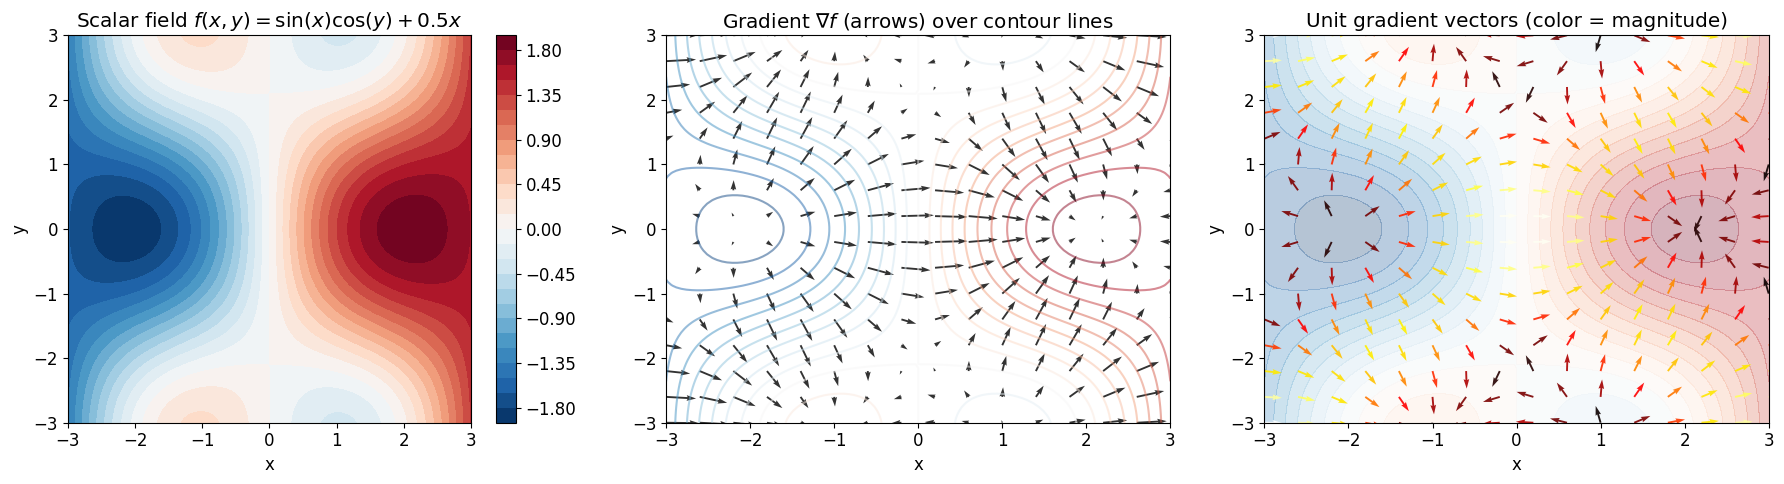

In [7]:
# Visualize: contour plot of scalar field + quiver plot of gradient
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
Z = scalar_field(X, Y)

# Gradient on a coarser grid for quiver arrows
x_q = np.linspace(-3, 3, 16)
y_q = np.linspace(-3, 3, 16)
Xq, Yq = np.meshgrid(x_q, y_q)
U, V = gradient_analytical(Xq, Yq)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Contour plot
cs = axes[0].contourf(X, Y, Z, levels=30, cmap='RdBu_r')
axes[0].set_title('Scalar field $f(x,y) = \\sin(x)\\cos(y) + 0.5x$')
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
plt.colorbar(cs, ax=axes[0])

# Gradient as quiver on top of contours
axes[1].contour(X, Y, Z, levels=20, cmap='RdBu_r', alpha=0.5)
axes[1].quiver(Xq, Yq, U, V, color='black', alpha=0.8)
axes[1].set_title('Gradient $\\nabla f$ (arrows) over contour lines')
axes[1].set_xlabel('x'); axes[1].set_ylabel('y')

# Gradient magnitude
grad_mag = np.sqrt(U**2 + V**2)
axes[2].contourf(X, Y, Z, levels=20, cmap='RdBu_r', alpha=0.3)
axes[2].quiver(Xq, Yq, U/grad_mag, V/grad_mag, grad_mag, cmap='hot', alpha=0.9)
axes[2].set_title('Unit gradient vectors (color = magnitude)')
axes[2].set_xlabel('x'); axes[2].set_ylabel('y')

plt.tight_layout()
plt.show()

**Notice**: The gradient arrows are always perpendicular to the contour lines, pointing toward higher values. This is the direction of steepest ascent. Gradient descent (used in training neural networks) moves in the *opposite* direction.

### Gradients with PyTorch on batches of points

In practice (e.g., computing score functions), we need gradients at many points simultaneously.

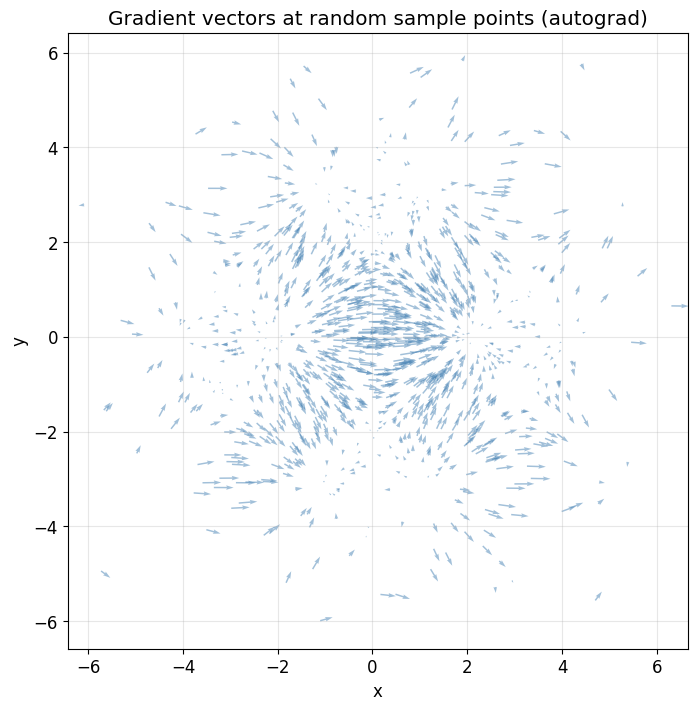

In [8]:
# Compute gradients at a batch of points using autograd
def batch_gradient(points):
    """Compute gradient of f(x,y) = sin(x)*cos(y) + 0.5*x at a batch of (x,y) points."""
    points = points.clone().requires_grad_(True)
    x, y = points[:, 0], points[:, 1]
    f = torch.sin(x) * torch.cos(y) + 0.5 * x
    # Sum so we can call backward (scalar output)
    f.sum().backward()
    return points.grad

# Random batch of 1000 points
pts = torch.randn(1000, 2) * 2
grads = batch_gradient(pts)

plt.figure(figsize=(8, 8))
plt.quiver(pts[:, 0].numpy(), pts[:, 1].numpy(),
           grads[:, 0].numpy(), grads[:, 1].numpy(),
           alpha=0.5, color='steelblue')
plt.title('Gradient vectors at random sample points (autograd)')
plt.xlabel('x'); plt.ylabel('y')
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

### 2.1 How autograd computes a gradient: vector–Jacobian products

For $f:\mathbb{R}^n\to\mathbb{R}^m$ with Jacobian $J$ ($m\times n$), reverse-mode autograd (`.backward()`) never builds $J$. It computes a **vector–Jacobian product** (VJP) $u^\top J$ for a vector $u$ you supply: by default $u = 1$ for a scalar output, or the `grad_outputs` argument otherwise. The cost is roughly one extra forward pass, **independent of $n$**.

This matters a lot for diffusion:

- A **scalar** energy $E: \mathbb{R}^{n}\to\mathbb{R}$ has a $1\times n$ Jacobian, so one backward pass gives the whole gradient $\nabla_x E$, even for a $256\times256\times3$ image ($n\approx 200{,}000$). That's why notebook 7 can get a score from an energy and notebook 6 can steer with $\nabla_x E$.
- Finite differences would need $n+1$ evaluations of $E$.
- `.sum().backward()` on a batch works because the samples are independent: the gradient of a sum of per-sample energies, taken w.r.t. sample $i$, only involves sample $i$'s own energy.
- The opposite mode, a **Jacobian–vector product** $J v$ (forward mode), costs about one pass as well. Building the *full* Jacobian of a vector field $\mathbb{R}^n \to \mathbb{R}^n$ costs $n$ passes, which is why exact divergences are expensive in high dimension (see §6.2).

In [9]:
import time
torch.manual_seed(0)
n = 2000
W1 = torch.randn(n, 256, dtype=torch.float64) / n**0.5
w2 = torch.randn(256, dtype=torch.float64) / 16

def E_fn(x):
    # A scalar 'energy' R^n -> R built from a random one-hidden-layer network.
    return torch.tanh(x @ W1) @ w2

x = torch.randn(n, dtype=torch.float64)

# Reverse mode: ONE backward pass gives all n partial derivatives
t0 = time.perf_counter()
xr = x.clone().requires_grad_(True)
E_fn(xr).backward()
g_autograd = xr.grad
t_ag = time.perf_counter() - t0

# Finite differences: one extra function evaluation PER coordinate
t0 = time.perf_counter()
h = 1e-6
E0 = E_fn(x)
I_n = torch.eye(n, dtype=torch.float64)
g_fd = torch.stack([(E_fn(x + h * I_n[i]) - E0) / h for i in range(n)])
t_fd = time.perf_counter() - t0

print(f"n = {n} inputs")
print(f"autograd:          {t_ag*1e3:8.1f} ms")
print(f"finite differences:{t_fd*1e3:8.1f} ms   ({n} extra evaluations)")
print(f"max |difference|:  {(g_autograd - g_fd).abs().max():.2e}  (finite-difference truncation error)")

# VJP and JVP for a vector-valued map F: R^n -> R^n, without building the n x n Jacobian
F = lambda z: torch.tanh(z @ W1) @ W1.T
u = torch.randn(n, dtype=torch.float64)
_, vjp = torch.autograd.functional.vjp(F, x, u)      # u^T J
_, jvp = torch.autograd.functional.jvp(F, x, u)      # J u
J = torch.autograd.functional.jacobian(F, x)         # the expensive way: n passes
print(f"\nVJP matches u^T J: {torch.allclose(vjp, u @ J)},   JVP matches J u: {torch.allclose(jvp, J @ u)}")

n = 2000 inputs
autograd:               0.6 ms
finite differences:   130.3 ms   (2000 extra evaluations)
max |difference|:  1.36e-09  (finite-difference truncation error)



VJP matches u^T J: True,   JVP matches J u: True


---
## 3. Vector Fields

A **vector field** assigns a vector to every point in space: $\mathbf{F}: \mathbb{R}^n \to \mathbb{R}^n$.

In diffusion models, vector fields appear everywhere:
- The **score function** $\nabla_x \log p(x)$ is a vector field
- In **flow matching**, the model learns a **velocity field** $v_\theta(x, t)$
- The **denoising direction** at each point is a vector field

Let's visualize several important types.

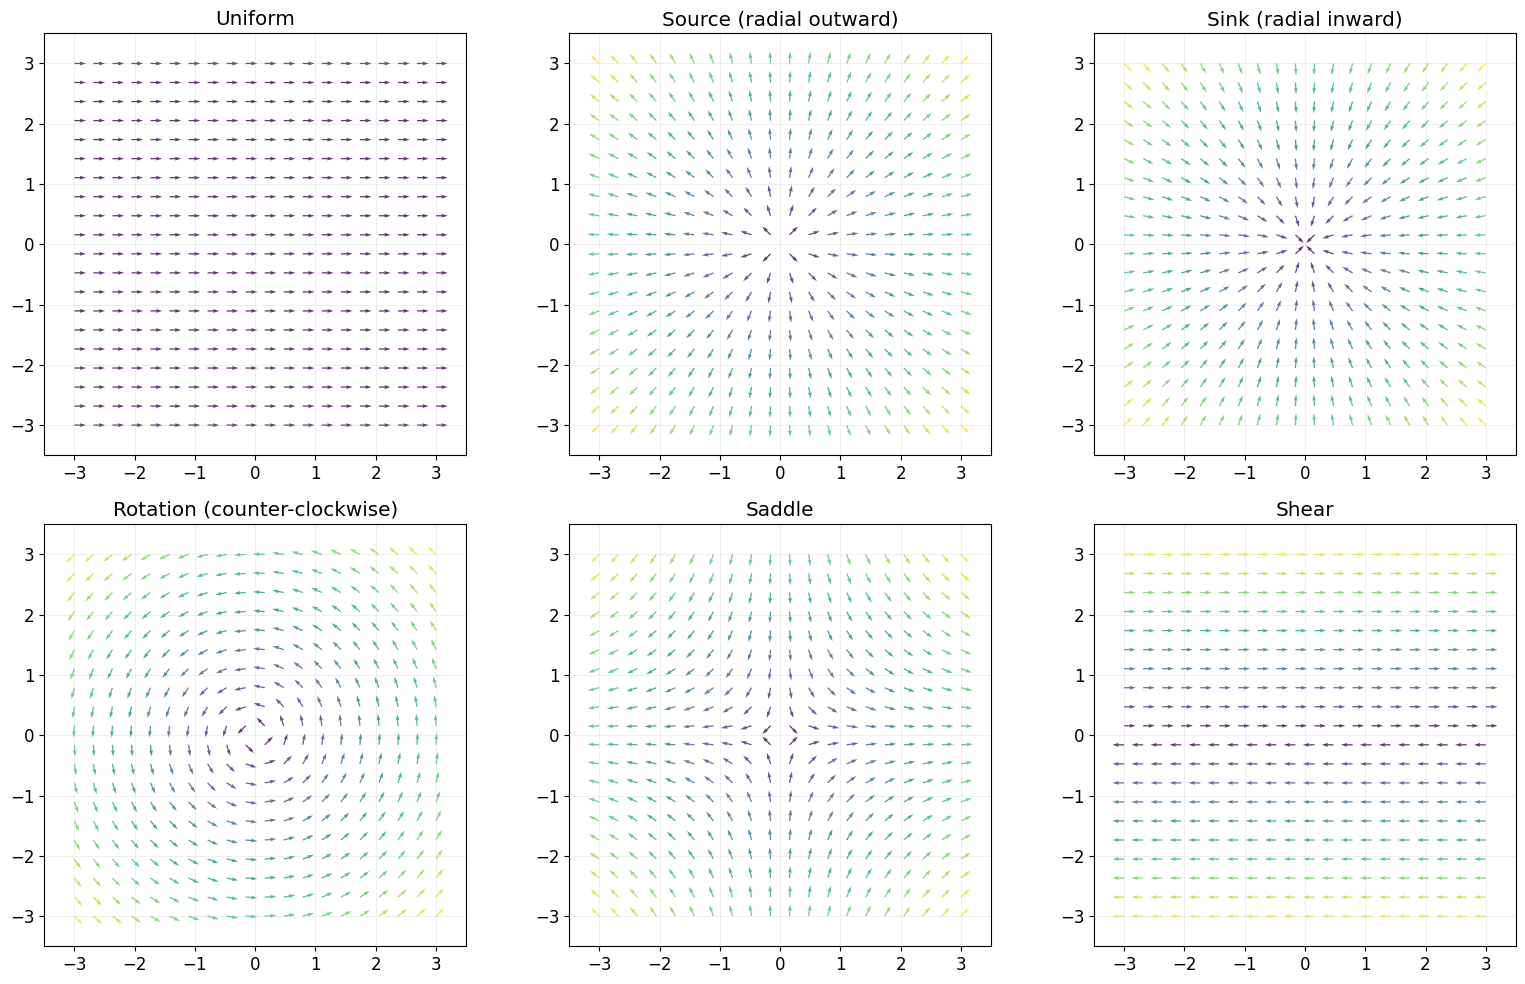

In [10]:
x = np.linspace(-3, 3, 20)
y = np.linspace(-3, 3, 20)
X, Y = np.meshgrid(x, y)

# Define various vector fields
fields = {
    'Uniform': (np.ones_like(X), np.zeros_like(Y)),
    'Source (radial outward)': (X, Y),
    'Sink (radial inward)': (-X, -Y),
    'Rotation (counter-clockwise)': (-Y, X),
    'Saddle': (X, -Y),
    'Shear': (Y, np.zeros_like(X)),
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, (U, V)) in zip(axes.flat, fields.items()):
    magnitude = np.sqrt(U**2 + V**2)
    magnitude = np.where(magnitude == 0, 1, magnitude)  # avoid /0
    ax.quiver(X, Y, U/magnitude, V/magnitude, magnitude, cmap='viridis', alpha=0.8)
    ax.set_title(name)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

### Streamlines

Streamlines show the paths that a particle would follow if placed in the vector field. This is directly related to how ODE solvers trace trajectories in flow matching.

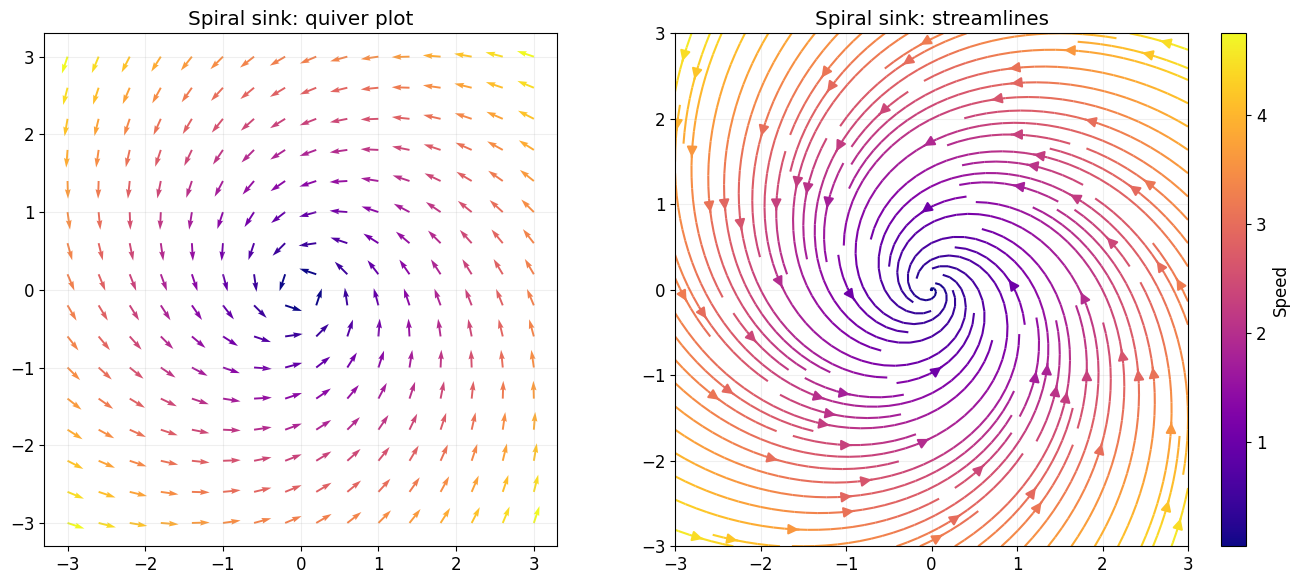

In [11]:
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)

# A more interesting field: spiraling inward
U = -Y - 0.5 * X
V = X - 0.5 * Y
speed = np.sqrt(U**2 + V**2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Quiver
x_q = np.linspace(-3, 3, 16)
y_q = np.linspace(-3, 3, 16)
Xq, Yq = np.meshgrid(x_q, y_q)
Uq = -Yq - 0.5 * Xq
Vq = Xq - 0.5 * Yq
mag_q = np.sqrt(Uq**2 + Vq**2)
ax1.quiver(Xq, Yq, Uq/mag_q, Vq/mag_q, mag_q, cmap='plasma')
ax1.set_title('Spiral sink: quiver plot')
ax1.set_aspect('equal')
ax1.grid(True, alpha=0.2)

# Streamlines
strm = ax2.streamplot(X, Y, U, V, color=speed, cmap='plasma',
                       density=1.5, linewidth=1.5, arrowsize=1.5)
ax2.set_title('Spiral sink: streamlines')
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.2)
plt.colorbar(strm.lines, ax=ax2, label='Speed')

plt.tight_layout()
plt.show()

---
## 4. Divergence

The **divergence** of a vector field $\mathbf{F} = (F_x, F_y)$ measures how much the field "spreads out" from a point:

$$\text{div}(\mathbf{F}) = \nabla \cdot \mathbf{F} = \frac{\partial F_x}{\partial x} + \frac{\partial F_y}{\partial y}$$

- **Positive divergence** = source (fluid flowing outward)
- **Negative divergence** = sink (fluid flowing inward)
- **Zero divergence** = incompressible flow (what goes in must come out)

Divergence appears in the **continuity equation** governing how probability density evolves under a flow — a core concept in continuous normalizing flows and flow matching.

In [3]:
# Compute divergence numerically (finite differences on a grid)
def divergence_numerical(U, V, dx, dy):
    """Compute divergence using central differences on a grid."""
    dFx_dx = np.gradient(U, dx, axis=1)  # dFx/dx along columns
    dFy_dy = np.gradient(V, dy, axis=0)  # dFy/dy along rows
    return dFx_dx + dFy_dy

# Compute divergence with PyTorch autograd
def divergence_autograd(field_fn, points):
    """
    field_fn: takes (x, y) tensors, returns (Fx, Fy) tensors
    points: (N, 2) tensor
    """
    points = points.clone().requires_grad_(True)
    x, y = points[:, 0], points[:, 1]
    Fx, Fy = field_fn(x, y)
    
    # dFx/dx
    dFx_dx = torch.autograd.grad(Fx.sum(), points, create_graph=True)[0][:, 0]
    # dFy/dy
    dFy_dy = torch.autograd.grad(Fy.sum(), points, create_graph=True)[0][:, 1]
    
    return dFx_dx + dFy_dy

# Example: source field F = (x, y) -> divergence should be 2 everywhere
def source_field(x, y):
    return x, y

pts = torch.randn(5, 2)
div = divergence_autograd(source_field, pts)
print("Divergence of source field F=(x,y) at random points:")
print(f"  Values: {div.detach().numpy()}")
print(f"  Expected: 2.0 everywhere (dFx/dx=1, dFy/dy=1)")

Divergence of source field F=(x,y) at random points:
  Values: [2. 2. 2. 2. 2.]
  Expected: 2.0 everywhere (dFx/dx=1, dFy/dy=1)


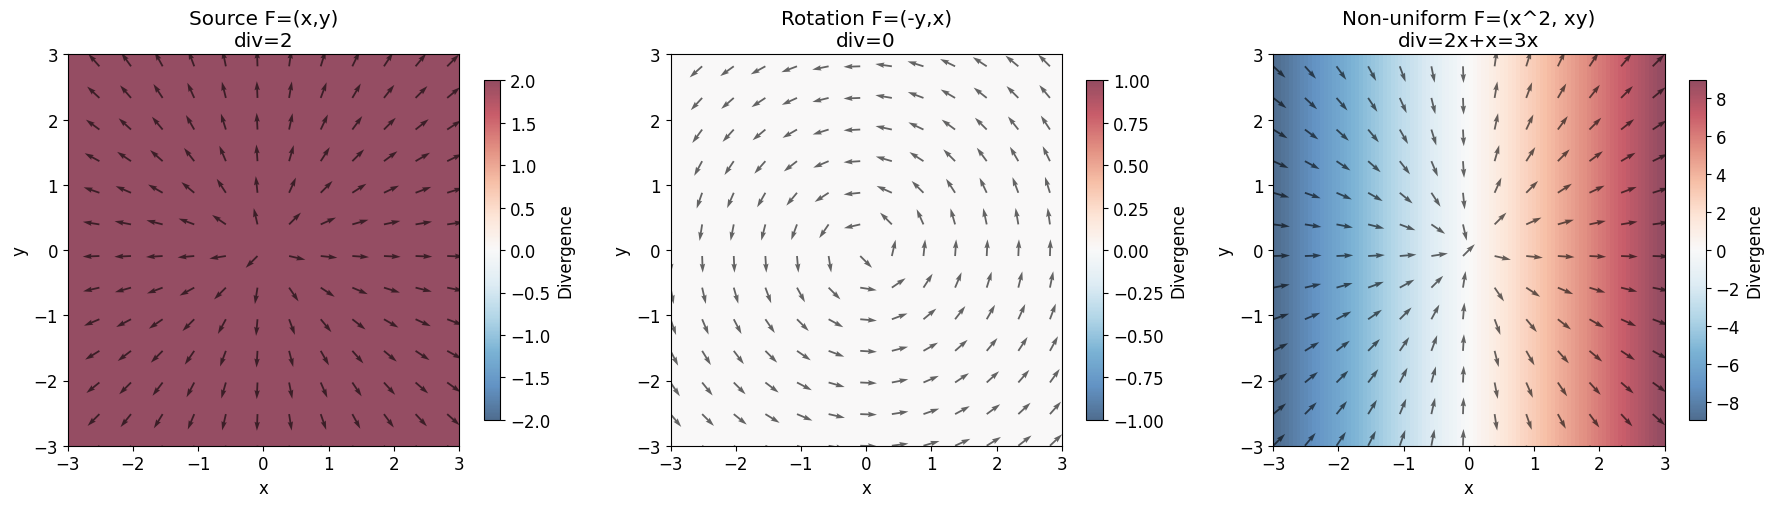

In [13]:
# Visualize divergence for several vector fields
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
dx = x[1] - x[0]
dy = y[1] - y[0]
X, Y = np.meshgrid(x, y)

# Three fields with different divergence properties
fields = {
    'Source F=(x,y)\ndiv=2': (X, Y),
    'Rotation F=(-y,x)\ndiv=0': (-Y, X),
    'Non-uniform F=(x^2, xy)\ndiv=2x+x=3x': (X**2, X*Y),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (U, V)) in zip(axes, fields.items()):
    div = divergence_numerical(U, V, dx, dy)
    
    # Color background by divergence
    vmax = max(abs(div.min()), abs(div.max()))
    if vmax == 0: vmax = 1
    im = ax.imshow(div, extent=[-3, 3, -3, 3], origin='lower',
                    cmap='RdBu_r', vmin=-vmax, vmax=vmax, alpha=0.7)
    
    # Overlay quiver
    skip = 8
    Us, Vs = U[::skip, ::skip], V[::skip, ::skip]
    mag = np.sqrt(Us**2 + Vs**2)
    mag = np.where(mag == 0, 1, mag)
    ax.quiver(X[::skip, ::skip], Y[::skip, ::skip],
              Us/mag, Vs/mag, color='black', alpha=0.6)
    
    ax.set_title(name)
    plt.colorbar(im, ax=ax, label='Divergence', shrink=0.8)
    ax.set_xlabel('x'); ax.set_ylabel('y')

plt.tight_layout()
plt.show()

**Key insight**: Pure rotation has zero divergence — nothing is being created or destroyed, just swirled around. This connects to the idea of **divergence-free flows** which preserve probability mass.

---
## 5. Curl

The **curl** measures how much a vector field "rotates" around a point.

In 2D, for $\mathbf{F} = (F_x, F_y)$, the curl is a scalar (the $z$-component of the 3D curl):

$$\text{curl}(\mathbf{F}) = \frac{\partial F_y}{\partial x} - \frac{\partial F_x}{\partial y}$$

In 3D, for $\mathbf{F} = (F_x, F_y, F_z)$:

$$\nabla \times \mathbf{F} = \left( \frac{\partial F_z}{\partial y} - \frac{\partial F_y}{\partial z},\; \frac{\partial F_x}{\partial z} - \frac{\partial F_z}{\partial x},\; \frac{\partial F_y}{\partial x} - \frac{\partial F_x}{\partial y} \right)$$

An important identity: **the gradient of any scalar field is curl-free** ($\nabla \times (\nabla f) = 0$). This means score functions (which are gradients of log-probability) have zero curl — they are *conservative* vector fields.

In [14]:
# Compute 2D curl numerically
def curl_2d_numerical(U, V, dx, dy):
    """Curl in 2D: dFy/dx - dFx/dy"""
    dFy_dx = np.gradient(V, dx, axis=1)
    dFx_dy = np.gradient(U, dy, axis=0)
    return dFy_dx - dFx_dy

# Compute 2D curl with autograd
def curl_2d_autograd(field_fn, points):
    points = points.clone().requires_grad_(True)
    x, y = points[:, 0], points[:, 1]
    Fx, Fy = field_fn(x, y)
    
    dFy_dx = torch.autograd.grad(Fy.sum(), points, create_graph=True)[0][:, 0]
    dFx_dy = torch.autograd.grad(Fx.sum(), points, create_graph=True)[0][:, 1]
    
    return dFy_dx - dFx_dy

# Test: rotation field F=(-y, x) should have curl = 2
def rotation_field(x, y):
    return -y, x

pts = torch.randn(5, 2)
curl = curl_2d_autograd(rotation_field, pts)
print("Curl of rotation field F=(-y, x):")
print(f"  Values: {curl.detach().numpy()}")
print(f"  Expected: 2.0 everywhere")

# Test: gradient field (curl-free)
# Gradient of f(x,y) = x^2 + y^2 is F = (2x, 2y)
def gradient_field(x, y):
    return 2*x, 2*y

curl_grad = curl_2d_autograd(gradient_field, pts)
print(f"\nCurl of gradient field F=(2x, 2y):")
print(f"  Values: {curl_grad.detach().numpy()}")
print(f"  Expected: 0.0 everywhere (gradients are curl-free!)")

Curl of rotation field F=(-y, x):
  Values: [2. 2. 2. 2. 2.]
  Expected: 2.0 everywhere

Curl of gradient field F=(2x, 2y):
  Values: [0. 0. 0. 0. 0.]
  Expected: 0.0 everywhere (gradients are curl-free!)


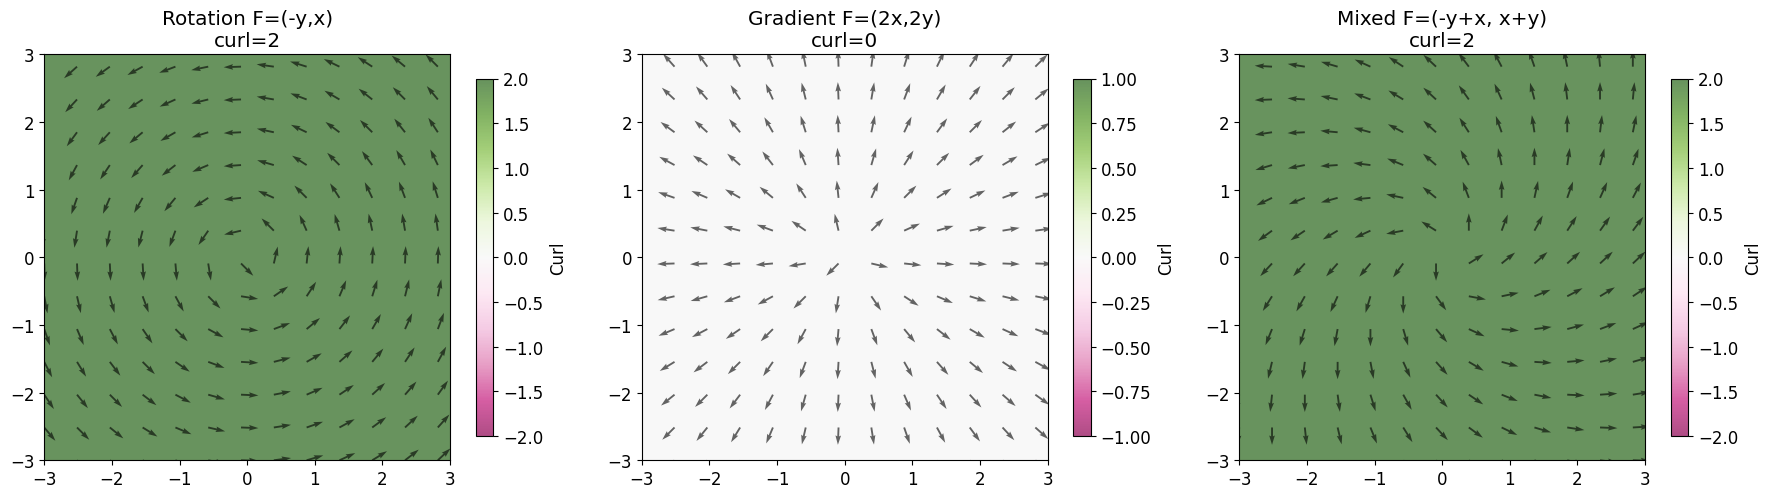

In [15]:
# Visualize curl for different fields
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
dx = x[1] - x[0]; dy = y[1] - y[0]
X, Y = np.meshgrid(x, y)

fields = {
    'Rotation F=(-y,x)\ncurl=2': (-Y, X),
    'Gradient F=(2x,2y)\ncurl=0': (2*X, 2*Y),
    'Mixed F=(-y+x, x+y)\ncurl=2': (-Y + X, X + Y),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (U, V)) in zip(axes, fields.items()):
    c = curl_2d_numerical(U, V, dx, dy)
    
    vmax = max(abs(c.min()), abs(c.max()))
    if vmax == 0: vmax = 1
    im = ax.imshow(c, extent=[-3, 3, -3, 3], origin='lower',
                    cmap='PiYG', vmin=-vmax, vmax=vmax, alpha=0.7)
    
    skip = 8
    Us, Vs = U[::skip, ::skip], V[::skip, ::skip]
    mag = np.sqrt(Us**2 + Vs**2)
    mag = np.where(mag == 0, 1, mag)
    ax.quiver(X[::skip, ::skip], Y[::skip, ::skip],
              Us/mag, Vs/mag, color='black', alpha=0.6)
    
    ax.set_title(name)
    plt.colorbar(im, ax=ax, label='Curl', shrink=0.8)

plt.tight_layout()
plt.show()

### Helmholtz decomposition (conceptual)

In 2D and 3D, any smooth, sufficiently decaying vector field can be decomposed into:
$$\mathbf{F} = -\nabla \phi + \nabla \times \mathbf{A}$$

- A **curl-free** (irrotational) part $-\nabla \phi$: this is what gradient/score fields look like.
- A **divergence-free** (solenoidal) part $\nabla \times \mathbf{A}$: pure circulation.

### Conservative fields in $n$ dimensions

The cross product (and hence "curl" as a vector) only exists in 3D, but diffusion models live in $\mathbb{R}^{1024}$ and beyond. The general statement uses the Jacobian $J_{ij} = \partial F_i / \partial x_j$:

$$\mathbf{F} = \nabla \phi \text{ for some scalar } \phi \quad\Longleftrightarrow\quad J = J^\top \text{ everywhere (on a simply-connected domain)}$$

For a gradient field, $J$ is the **Hessian** of $\phi$, and Hessians are symmetric because mixed partial derivatives commute. The antisymmetric part $\tfrac12(J - J^\top)$ is the $n$-dimensional generalisation of curl: in 2D its single independent entry is $\tfrac12\,\text{curl}$.

Why you care:

- The *true* score $\nabla_x \log p_t(x)$ is conservative, being a gradient.
- A network that outputs a score or noise prediction **directly** (notebooks 1–3) can represent non-conservative fields. Training only pushes it *toward* a symmetric Jacobian.
- An energy network with $s_\theta = -\nabla_x E_\theta$ (notebook 7) is conservative **by construction**.

Let's test this on two random networks.

In [16]:
torch.manual_seed(0)
d = 6
energy_net = nn.Sequential(nn.Linear(d, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 1))
vector_net = nn.Sequential(nn.Linear(d, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, d))

def energy_score(z):
    # s(z) = -grad E(z): conservative by construction.
    with torch.enable_grad():
        z = z if z.requires_grad else z.requires_grad_(True)
        return -torch.autograd.grad(energy_net(z).sum(), z, create_graph=True)[0]

def asymmetry(J):
    # ||J - J^T|| / ||J||: 0 for a conservative field.
    return ((J - J.T).norm() / J.norm()).item()

for i in range(3):
    x = torch.randn(d)
    J_energy = torch.autograd.functional.jacobian(energy_score, x)
    J_vector = torch.autograd.functional.jacobian(vector_net, x)
    print(f"point {i}:  energy-network score asymmetry = {asymmetry(J_energy):.1e}   "
          f"direct vector network asymmetry = {asymmetry(J_vector):.2f}")

point 0:  energy-network score asymmetry = 2.4e-07   direct vector network asymmetry = 1.49
point 1:  energy-network score asymmetry = 3.6e-07   direct vector network asymmetry = 1.28
point 2:  energy-network score asymmetry = 2.7e-07   direct vector network asymmetry = 1.27


The energy-derived field is symmetric up to float32 rounding; the direct vector network is not. Neither statement says anything about which one *learns better*. In practice, direct $\epsilon$/velocity networks are faster to train and work extremely well, and the EBM pays for its guarantee with second-order gradients (0c Part 5).

---
## 6. Jacobians

The **Jacobian matrix** generalizes the derivative to vector-valued functions $\mathbf{f}: \mathbb{R}^n \to \mathbb{R}^m$:

$$J = \begin{pmatrix} \frac{\partial f_1}{\partial x_1} & \cdots & \frac{\partial f_1}{\partial x_n} \\ \vdots & \ddots & \vdots \\ \frac{\partial f_m}{\partial x_1} & \cdots & \frac{\partial f_m}{\partial x_n} \end{pmatrix}$$

Key uses in generative models:
- **Normalizing flows**: The log-determinant of the Jacobian tracks how probability density changes under a transformation
- **Divergence** is the trace of the Jacobian: $\text{div}(\mathbf{F}) = \text{tr}(J)$
- **Continuous normalizing flows**: Use the instantaneous change-of-variables formula involving the trace of the Jacobian

In [17]:
# Compute Jacobian with torch.autograd.functional
def transform(x):
    """A nonlinear 2D -> 2D transform: (x1, x2) -> (x1^2 + x2, sin(x1) + x2^2)"""
    return torch.stack([x[0]**2 + x[1], torch.sin(x[0]) + x[1]**2])

x0 = torch.tensor([1.0, 2.0])

# PyTorch functional Jacobian
J = torch.autograd.functional.jacobian(transform, x0)
print("Jacobian of transform at (1, 2):")
print(J)
print(f"\nAnalytical Jacobian:")
print(f"  [[2*x1, 1   ], [cos(x1), 2*x2]]")
print(f"  [[2.0,  1.0 ], [{np.cos(1.0):.4f}, 4.0  ]]")

# Determinant — measures how the transform scales local area
det_J = torch.det(J)
print(f"\nDeterminant: {det_J.item():.4f}")
print(f"  |det| > 1 means local expansion, |det| < 1 means contraction")

# Trace = divergence
print(f"\nTrace (= divergence): {torch.trace(J).item():.4f}")

Jacobian of transform at (1, 2):
tensor([[2.0000, 1.0000],
        [0.5403, 4.0000]])

Analytical Jacobian:
  [[2*x1, 1   ], [cos(x1), 2*x2]]
  [[2.0,  1.0 ], [0.5403, 4.0  ]]

Determinant: 7.4597
  |det| > 1 means local expansion, |det| < 1 means contraction

Trace (= divergence): 6.0000


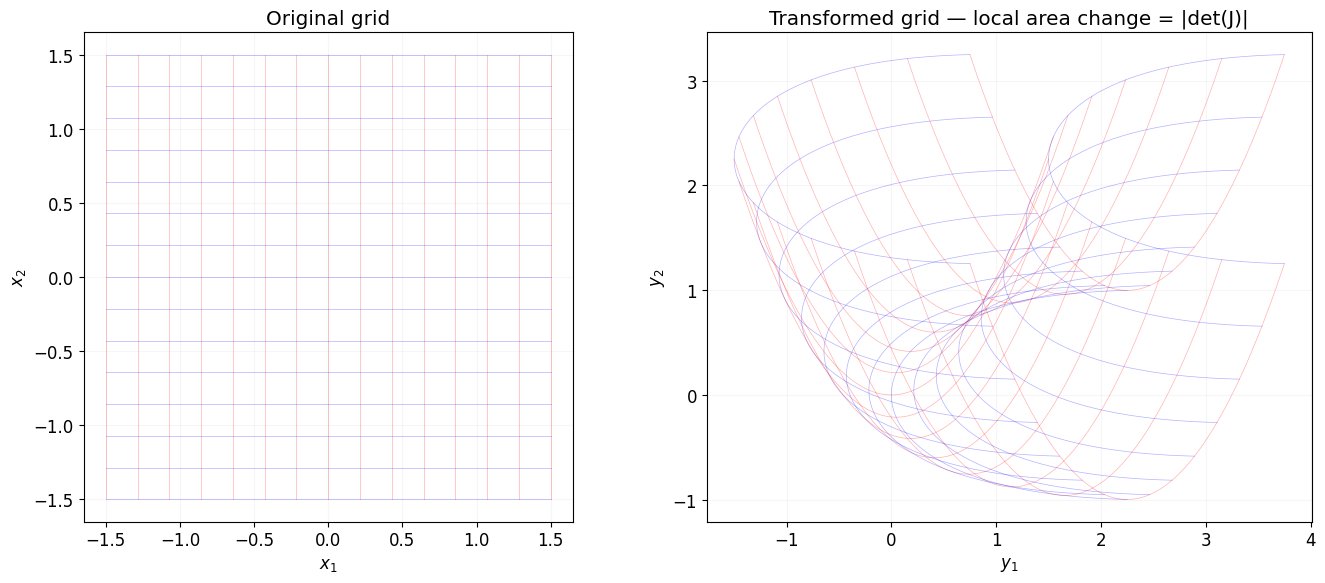

In [18]:
# Visualize how a transformation warps a grid
def np_transform(x1, x2):
    return x1**2 + x2, np.sin(x1) + x2**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Draw a grid in the original space and its image under the transform
t = np.linspace(-1.5, 1.5, 15)
for val in t:
    # Horizontal lines
    s = np.linspace(-1.5, 1.5, 200)
    ax1.plot(s, np.full_like(s, val), 'b-', alpha=0.3, linewidth=0.5)
    y1, y2 = np_transform(s, np.full_like(s, val))
    ax2.plot(y1, y2, 'b-', alpha=0.3, linewidth=0.5)
    
    # Vertical lines
    ax1.plot(np.full_like(s, val), s, 'r-', alpha=0.3, linewidth=0.5)
    y1, y2 = np_transform(np.full_like(s, val), s)
    ax2.plot(y1, y2, 'r-', alpha=0.3, linewidth=0.5)

ax1.set_title('Original grid')
ax1.set_aspect('equal'); ax1.grid(True, alpha=0.1)
ax1.set_xlabel('$x_1$'); ax1.set_ylabel('$x_2$')

ax2.set_title('Transformed grid — local area change = |det(J)|')
ax2.set_aspect('equal'); ax2.grid(True, alpha=0.1)
ax2.set_xlabel('$y_1$'); ax2.set_ylabel('$y_2$')

plt.tight_layout()
plt.show()

### The change-of-variables formula

If $\mathbf{y} = \mathbf{f}(\mathbf{x})$ is an invertible transformation, then probability densities transform as:

$$p_Y(\mathbf{y}) = p_X(\mathbf{x}) \cdot |\det(J)|^{-1}$$

In log space: $\log p_Y(\mathbf{y}) = \log p_X(\mathbf{x}) - \log |\det(J)|$

This is the foundation of **normalizing flows** — chain invertible transforms and track the log-determinant of each Jacobian to compute exact likelihoods.

### 6.1 Instantaneous change of variables (continuous normalizing flows)

Now chain *infinitely many infinitesimal* transforms: let particles follow $\frac{dx}{dt} = v(x, t)$. Over a tiny step $x \mapsto x + v\,dt$, the Jacobian is $I + J_v\,dt$ and $\log|\det(I + J_v\,dt)| \approx \text{tr}(J_v)\,dt = (\nabla\cdot v)\,dt$. So along a trajectory:

$$\frac{d}{dt} \log p_t\big(x(t)\big) = -\,\nabla \cdot v\big(x(t), t\big)$$

**Divergence is the rate at which a flow dilutes probability density.** This is the Lagrangian form of the continuity equation $\partial_t p + \nabla\cdot(p\,v) = 0$ (0c, THEORY.md §7), and it is how a flow-matching or probability-flow model computes **exact log-likelihoods**: integrate the ODE and accumulate $-\int \nabla\cdot v\,dt$.

Let's verify it on a linear field $v(x) = A x$, where everything is known in closed form: if $x(0) \sim \mathcal{N}(0, I)$ then $x(t) = e^{At}x(0) \sim \mathcal{N}(0, e^{At}e^{A^\top t})$.

In [19]:
from scipy.linalg import expm
from scipy.stats import multivariate_normal

A = np.array([[-0.5, -1.0],
              [ 1.0, -0.2]])          # a spiral sink: trace(A) = -0.7 < 0 -> density concentrates
t_end, n_steps = 2.0, 2000
dt = t_end / n_steps

rng = np.random.default_rng(0)
x = rng.standard_normal((5, 2))
logp = multivariate_normal(np.zeros(2), np.eye(2)).logpdf(x)   # log p_0 at the start points

for _ in range(n_steps):
    x = x + dt * (x @ A.T)                     # Euler step of dx/dt = A x
    logp = logp - dt * np.trace(A)             # d log p / dt = -div v = -tr(A)

cov_t = expm(A * t_end) @ expm(A * t_end).T
exact = multivariate_normal(np.zeros(2), cov_t).logpdf(x)
print("log p_t(x(t)) tracked along trajectories:", logp.round(4))
print("exact log-density of N(0, e^At e^A't):   ", exact.round(4))

log p_t(x(t)) tracked along trajectories: [-0.4545 -0.6484 -0.6467 -1.7366 -1.4861]
exact log-density of N(0, e^At e^A't):    [-0.4545 -0.6488 -0.6471 -1.7387 -1.4881]


### 6.2 The Hutchinson trace estimator

For a neural field in $d$ dimensions, the exact divergence $\text{tr}(J)$ needs $d$ backward passes, which is too expensive for images. The **Hutchinson estimator** uses random probe vectors $z$ with $\mathbb{E}[zz^\top] = I$ (e.g. random $\pm1$ entries):

$$\text{tr}(J) = \mathbb{E}_z\big[z^\top J z\big]$$

Each sample needs **one VJP** ($z^\top J$, §2.1) followed by a dot product with $z$. The estimate is unbiased, and its noise shrinks like $1/\sqrt{\#\text{probes}}$. FFJORD and likelihood evaluation for diffusion/flow models use exactly this.

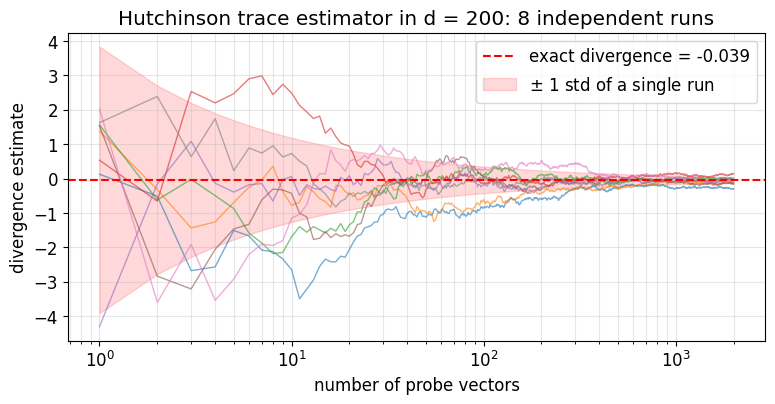

mean over all 16000 probes: -0.085   (exact -0.039, std. error 0.031)


In [20]:
torch.manual_seed(0)
d = 200
field = nn.Sequential(nn.Linear(d, 256), nn.Tanh(), nn.Linear(256, d))
x = torch.randn(d)

exact_div = torch.trace(torch.autograd.functional.jacobian(field, x)).item()   # d backward passes

def hutchinson_runs(field, x, n_runs, n_probes):
    # n_runs independent Hutchinson estimates, each averaging n_probes probes.
    # All probes are done in ONE batched backward pass: row k of the batch gives z_k^T J.
    X = x.repeat(n_runs * n_probes, 1).requires_grad_(True)
    Z = torch.randint(0, 2, X.shape).float() * 2 - 1          # Rademacher +-1 probes
    zJ = torch.autograd.grad(field(X), X, grad_outputs=Z)[0]   # vector-Jacobian products
    per_probe = (zJ * Z).sum(1).reshape(n_runs, n_probes)      # z^T J z for every probe
    return per_probe

per_probe = hutchinson_runs(field, x, n_runs=8, n_probes=2000).detach().numpy()
probes = np.arange(1, per_probe.shape[1] + 1)
running = np.cumsum(per_probe, axis=1) / probes
sd = per_probe.std()

plt.figure(figsize=(9, 4))
for r in running:
    plt.semilogx(probes, r, alpha=0.6, lw=1)
plt.axhline(exact_div, color='r', ls='--', label=f'exact divergence = {exact_div:.3f}')
plt.fill_between(probes, exact_div - sd / np.sqrt(probes), exact_div + sd / np.sqrt(probes),
                 color='r', alpha=0.15, label='$\\pm$ 1 std of a single run')
plt.xlabel('number of probe vectors'); plt.ylabel('divergence estimate')
plt.title(f'Hutchinson trace estimator in d = {d}: 8 independent runs'); plt.legend(); plt.grid(alpha=0.3, which='both')
plt.show()
print(f"mean over all {per_probe.size} probes: {per_probe.mean():.3f}   (exact {exact_div:.3f}, "
      f"std. error {sd / np.sqrt(per_probe.size):.3f})")

---
## 7. Numerical Integration

Integration is the reverse of differentiation. We need it to:
- Compute expectations $\mathbb{E}[f(x)] = \int f(x) p(x) dx$
- Normalize probability distributions
- Solve ODEs (next section)

### 7.1 Deterministic quadrature

In [21]:
from scipy import integrate

# Function to integrate: f(x) = e^(-x^2) (Gaussian bell curve)
def g(x):
    return np.exp(-x**2)

# Analytical result: integral from -inf to inf = sqrt(pi)
exact = np.sqrt(np.pi)
print(f"Exact integral of e^(-x^2) from -inf to inf: {exact:.6f}")

# Method 1: Trapezoidal rule
x = np.linspace(-5, 5, 100)
trap_result = np.trapezoid(g(x), x)
print(f"Trapezoidal (100 pts, [-5,5]):  {trap_result:.6f}  (error: {abs(trap_result-exact):.2e})")

x = np.linspace(-5, 5, 1000)
trap_result2 = np.trapezoid(g(x), x)
print(f"Trapezoidal (1000 pts, [-5,5]): {trap_result2:.6f}  (error: {abs(trap_result2-exact):.2e})")

# Method 2: Simpson's rule (scipy)
x = np.linspace(-5, 5, 101)  # odd number of points
simp_result = integrate.simpson(g(x), x=x)
print(f"Simpson's (101 pts, [-5,5]):    {simp_result:.6f}  (error: {abs(simp_result-exact):.2e})")

# Method 3: Adaptive quadrature (scipy.integrate.quad)
quad_result, quad_error = integrate.quad(g, -np.inf, np.inf)
print(f"Adaptive quad (-inf, inf):      {quad_result:.6f}  (error: {quad_error:.2e})")

Exact integral of e^(-x^2) from -inf to inf: 1.772454
Trapezoidal (100 pts, [-5,5]):  1.772454  (error: 2.96e-12)
Trapezoidal (1000 pts, [-5,5]): 1.772454  (error: 2.73e-12)
Simpson's (101 pts, [-5,5]):    1.772454  (error: 2.74e-12)
Adaptive quad (-inf, inf):      1.772454  (error: 1.42e-08)


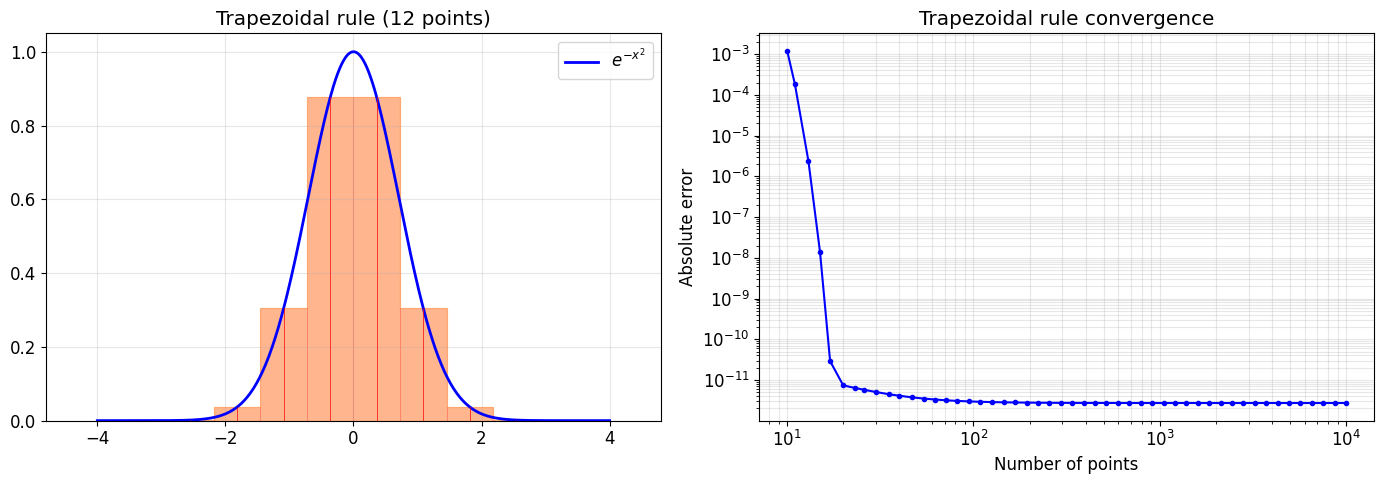

In [22]:
# Visualize the trapezoidal rule
x_fine = np.linspace(-4, 4, 500)
x_trap = np.linspace(-4, 4, 12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Coarse trapezoids
ax1.plot(x_fine, g(x_fine), 'b-', linewidth=2, label='$e^{-x^2}$')
ax1.fill_between(x_trap, 0, g(x_trap), alpha=0.3, color='orange', step='mid')
for xi in x_trap:
    ax1.plot([xi, xi], [0, g(xi)], 'r-', linewidth=0.5)
ax1.bar(x_trap, g(x_trap), width=x_trap[1]-x_trap[0], alpha=0.2, color='red',
        edgecolor='red', linewidth=0.5)
ax1.set_title(f'Trapezoidal rule (12 points)')
ax1.legend(); ax1.grid(True, alpha=0.3)

# Convergence study
n_points = np.logspace(1, 4, 50).astype(int)
errors = []
for n in n_points:
    x = np.linspace(-5, 5, n)
    result = np.trapezoid(g(x), x)
    errors.append(abs(result - exact))

ax2.loglog(n_points, errors, 'b.-')
ax2.set_xlabel('Number of points')
ax2.set_ylabel('Absolute error')
ax2.set_title('Trapezoidal rule convergence')
ax2.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

### 7.2 Monte Carlo integration

For high-dimensional integrals (common in ML), deterministic quadrature becomes impractical. **Monte Carlo integration** uses random sampling:

$$\int f(x) dx \approx \frac{V}{N} \sum_{i=1}^{N} f(x_i)$$

where $V$ is the volume of the integration domain and $x_i$ are random samples.

For computing expectations under a distribution $p(x)$:

$$\mathbb{E}_{p}[f(x)] = \int f(x) p(x) dx \approx \frac{1}{N} \sum_{i=1}^{N} f(x_i), \quad x_i \sim p(x)$$

This is how we estimate the training loss in diffusion models — sampling random timesteps and noise.

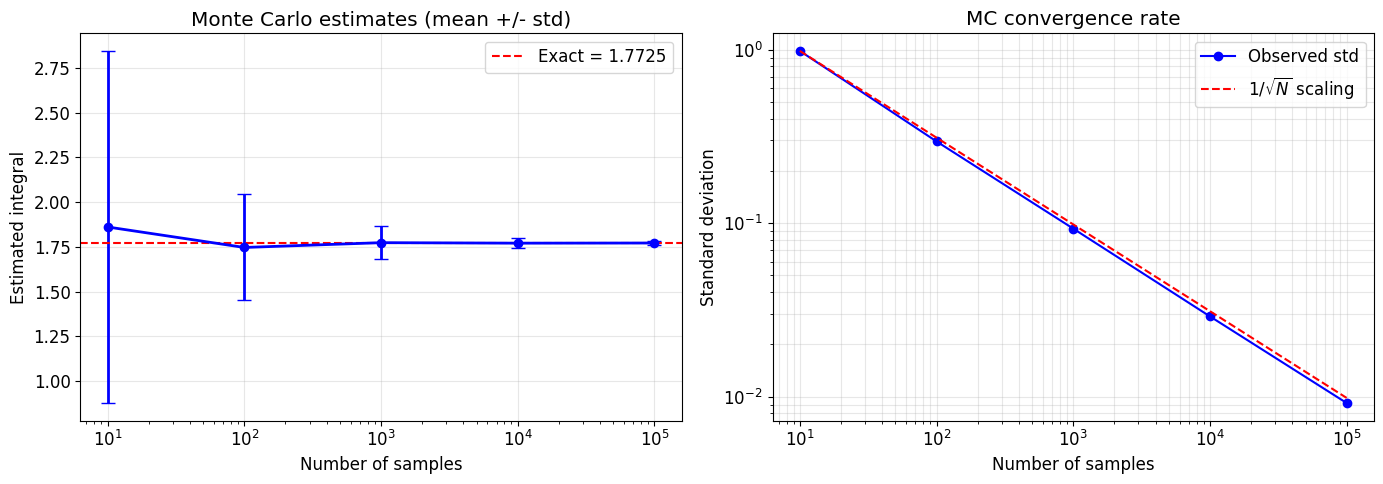

In [23]:
# Monte Carlo integration: estimate integral of e^(-x^2) over [-5, 5]
exact = np.sqrt(np.pi)
domain_length = 10.0  # from -5 to 5

sample_sizes = [10, 100, 1000, 10000, 100000]
n_trials = 200

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

means = []
stds = []
for N in sample_sizes:
    estimates = []
    for _ in range(n_trials):
        x_samples = np.random.uniform(-5, 5, N)
        estimate = domain_length * np.mean(g(x_samples))
        estimates.append(estimate)
    means.append(np.mean(estimates))
    stds.append(np.std(estimates))
    
ax1.errorbar(sample_sizes, means, yerr=stds, fmt='bo-', capsize=5, linewidth=2)
ax1.axhline(y=exact, color='r', linestyle='--', label=f'Exact = {exact:.4f}')
ax1.set_xscale('log')
ax1.set_xlabel('Number of samples')
ax1.set_ylabel('Estimated integral')
ax1.set_title('Monte Carlo estimates (mean +/- std)')
ax1.legend(); ax1.grid(True, alpha=0.3)

# Standard deviation decreases as 1/sqrt(N)
ax2.loglog(sample_sizes, stds, 'bo-', label='Observed std')
theoretical = stds[0] * np.sqrt(sample_sizes[0]) / np.sqrt(sample_sizes)
ax2.loglog(sample_sizes, theoretical, 'r--', label='$1/\\sqrt{N}$ scaling')
ax2.set_xlabel('Number of samples')
ax2.set_ylabel('Standard deviation')
ax2.set_title('MC convergence rate')
ax2.legend(); ax2.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

**Key insight**: Monte Carlo converges at rate $O(1/\sqrt{N})$ *regardless of dimension*. This is why it's the method of choice for high-dimensional integration (like computing expectations over pixel spaces).

In [24]:
# Computing expectations with PyTorch
# E[X^2] where X ~ N(0, 1) should be 1.0 (the variance of a standard normal)

N_samples = 100000
x = torch.randn(N_samples)  # sample from N(0, 1)
expectation = (x**2).mean()
print(f"E[X^2] where X ~ N(0,1): {expectation.item():.4f}  (exact: 1.0)")

# E[sin(X)] where X ~ N(0, 1) should be 0.0 (odd function, symmetric distribution)
expectation_sin = torch.sin(x).mean()
print(f"E[sin(X)]:              {expectation_sin.item():.4f}  (exact: 0.0)")

# E[e^X] where X ~ N(0, 1) = e^(1/2) by moment generating function
expectation_exp = torch.exp(x).mean()
print(f"E[e^X]:                 {expectation_exp.item():.4f}  (exact: {np.exp(0.5):.4f})")

E[X^2] where X ~ N(0,1): 1.0064  (exact: 1.0)
E[sin(X)]:              0.0017  (exact: 0.0)
E[e^X]:                 1.6545  (exact: 1.6487)


---
## 8. ODE Solving: Following Vector Fields

An **ordinary differential equation** (ODE) describes how a state evolves over time:

$$\frac{d\mathbf{x}}{dt} = \mathbf{v}(\mathbf{x}, t)$$

Given an initial condition $\mathbf{x}(0) = \mathbf{x}_0$, we want to find $\mathbf{x}(T)$.

This is *exactly* what happens in **flow matching**: the model learns a velocity field $v_\theta(x, t)$, and at inference time we solve the ODE to transport noise $x_0 \sim \mathcal{N}(0, I)$ to data $x_1$.

### 8.1 Euler method

The simplest ODE solver. Take small steps in the direction of the velocity:

$$\mathbf{x}_{n+1} = \mathbf{x}_n + h \cdot \mathbf{v}(\mathbf{x}_n, t_n)$$

where $h$ is the step size.

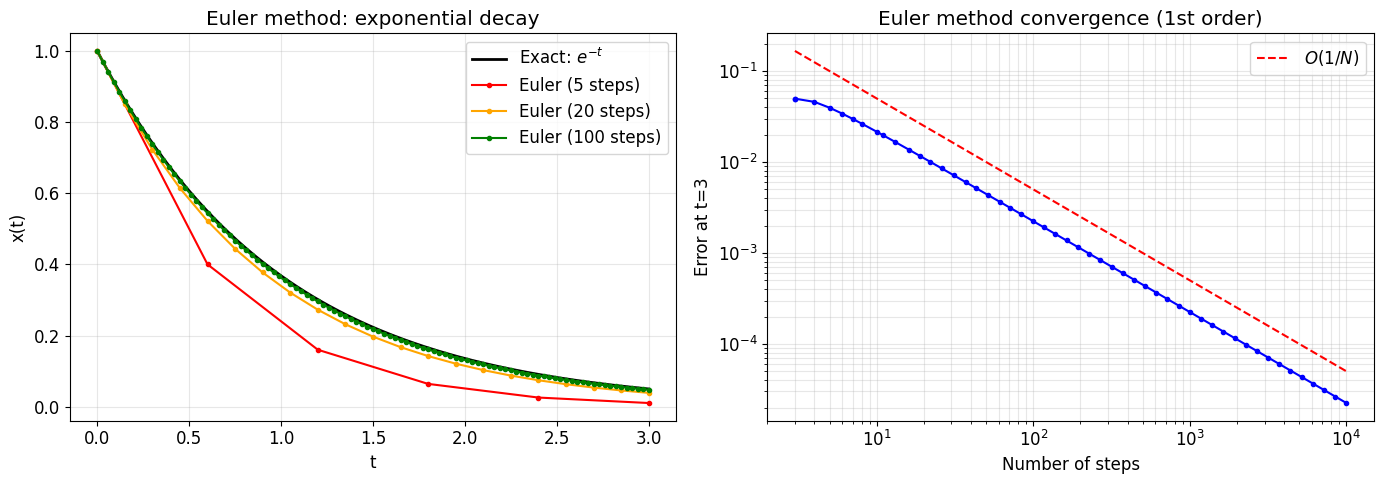

In [25]:
def euler_solve(v_fn, x0, t_span, n_steps):
    """
    Solve dx/dt = v(x, t) from t_span[0] to t_span[1].
    
    v_fn: function(x, t) -> dx/dt
    x0: initial condition (numpy array)
    t_span: (t_start, t_end)
    n_steps: number of Euler steps
    
    Returns: trajectory array of shape (n_steps+1, dim)
    """
    t_start, t_end = t_span
    h = (t_end - t_start) / n_steps
    
    x = np.array(x0, dtype=float)
    trajectory = [x.copy()]
    t = t_start
    
    for _ in range(n_steps):
        x = x + h * v_fn(x, t)
        t += h
        trajectory.append(x.copy())
    
    return np.array(trajectory)

# Test: solve dx/dt = -x (exponential decay), x(0) = 1
# Exact solution: x(t) = e^(-t)
v_decay = lambda x, t: -x

t_end = 3.0
t_exact = np.linspace(0, t_end, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(t_exact, np.exp(-t_exact), 'k-', linewidth=2, label='Exact: $e^{-t}$')
for n_steps, color in [(5, 'red'), (20, 'orange'), (100, 'green')]:
    traj = euler_solve(v_decay, [1.0], (0, t_end), n_steps)
    t_euler = np.linspace(0, t_end, n_steps + 1)
    ax1.plot(t_euler, traj[:, 0], 'o-', color=color, markersize=3, label=f'Euler ({n_steps} steps)')

ax1.set_xlabel('t'); ax1.set_ylabel('x(t)')
ax1.set_title('Euler method: exponential decay')
ax1.legend(); ax1.grid(True, alpha=0.3)

# Convergence: error vs step count
step_counts = np.logspace(0.5, 4, 50).astype(int)
errors = []
for n in step_counts:
    traj = euler_solve(v_decay, [1.0], (0, t_end), n)
    error = abs(traj[-1, 0] - np.exp(-t_end))
    errors.append(error)

ax2.loglog(step_counts, errors, 'b.-')
# Reference line: O(h) = O(1/n)
ax2.loglog(step_counts, 0.5/step_counts, 'r--', label='$O(1/N)$')
ax2.set_xlabel('Number of steps'); ax2.set_ylabel('Error at t=3')
ax2.set_title('Euler method convergence (1st order)')
ax2.legend(); ax2.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

### 8.2 Runge-Kutta 4th order (RK4)

RK4 achieves much better accuracy by evaluating the velocity at intermediate points:

$$\begin{aligned}
k_1 &= h \cdot v(x_n, t_n) \\
k_2 &= h \cdot v(x_n + k_1/2, t_n + h/2) \\
k_3 &= h \cdot v(x_n + k_2/2, t_n + h/2) \\
k_4 &= h \cdot v(x_n + k_3, t_n + h) \\
x_{n+1} &= x_n + \frac{1}{6}(k_1 + 2k_2 + 2k_3 + k_4)
\end{aligned}$$

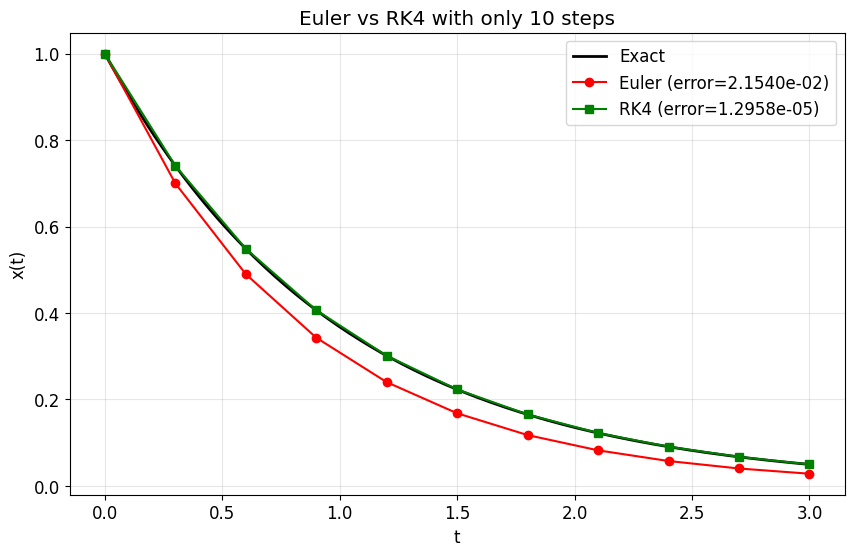

In [26]:
def rk4_solve(v_fn, x0, t_span, n_steps):
    """4th-order Runge-Kutta ODE solver."""
    t_start, t_end = t_span
    h = (t_end - t_start) / n_steps
    
    x = np.array(x0, dtype=float)
    trajectory = [x.copy()]
    t = t_start
    
    for _ in range(n_steps):
        k1 = h * v_fn(x, t)
        k2 = h * v_fn(x + k1/2, t + h/2)
        k3 = h * v_fn(x + k2/2, t + h/2)
        k4 = h * v_fn(x + k3, t + h)
        x = x + (k1 + 2*k2 + 2*k3 + k4) / 6
        t += h
        trajectory.append(x.copy())
    
    return np.array(trajectory)

# Compare Euler vs RK4 on exponential decay
n_steps = 10
traj_euler = euler_solve(v_decay, [1.0], (0, t_end), n_steps)
traj_rk4 = rk4_solve(v_decay, [1.0], (0, t_end), n_steps)
t_discrete = np.linspace(0, t_end, n_steps + 1)

plt.figure(figsize=(10, 6))
plt.plot(t_exact, np.exp(-t_exact), 'k-', linewidth=2, label='Exact')
plt.plot(t_discrete, traj_euler[:, 0], 'ro-', label=f'Euler (error={abs(traj_euler[-1,0]-np.exp(-t_end)):.4e})')
plt.plot(t_discrete, traj_rk4[:, 0], 'gs-', label=f'RK4 (error={abs(traj_rk4[-1,0]-np.exp(-t_end)):.4e})')
plt.xlabel('t'); plt.ylabel('x(t)')
plt.title(f'Euler vs RK4 with only {n_steps} steps')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

### 8.3 Following a 2D velocity field (particle trajectories)

This is the key geometric picture for flow matching: particles start at random positions and follow a learned velocity field to their destinations.

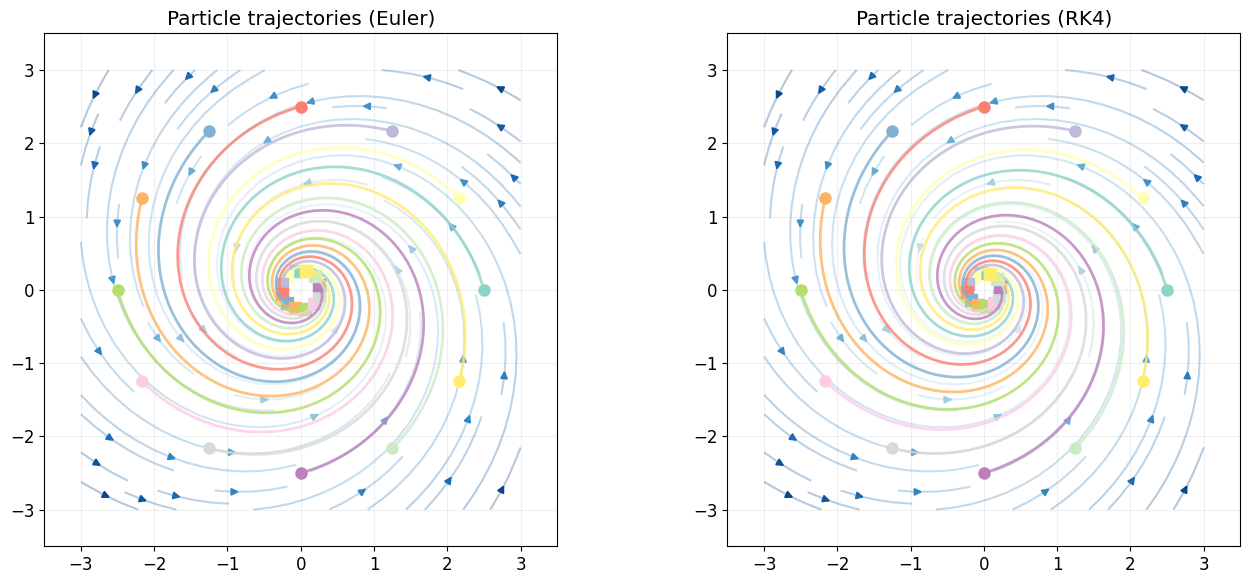

In [27]:
# Velocity field: spiral inward
def spiral_velocity(x, t):
    """A time-independent spiral velocity field."""
    return np.array([-x[1] - 0.3*x[0], x[0] - 0.3*x[1]])

# Launch particles from different starting positions
n_particles = 12
angles = np.linspace(0, 2*np.pi, n_particles, endpoint=False)
start_positions = 2.5 * np.stack([np.cos(angles), np.sin(angles)], axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Background streamlines
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
U = -Y - 0.3*X
V = X - 0.3*Y

for ax, (solver, name) in [(ax1, (euler_solve, 'Euler')), (ax2, (rk4_solve, 'RK4'))]:
    speed = np.sqrt(U**2 + V**2)
    strm = ax.streamplot(X, Y, U, V, color=speed, cmap='Blues', density=0.8)
    strm.lines.set_alpha(0.3)
    
    colors = plt.cm.Set3(np.linspace(0, 1, n_particles))
    for i, x0 in enumerate(start_positions):
        traj = solver(spiral_velocity, x0, (0, 8), 200)
        ax.plot(traj[:, 0], traj[:, 1], '-', color=colors[i], linewidth=2, alpha=0.8)
        ax.plot(traj[0, 0], traj[0, 1], 'o', color=colors[i], markersize=8)  # start
        ax.plot(traj[-1, 0], traj[-1, 1], 's', color=colors[i], markersize=8)  # end
    
    ax.set_title(f'Particle trajectories ({name})')
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

### 8.4 Time-dependent velocity field (flow matching preview)

In flow matching, the velocity field changes over time. Below, each noise sample $x_0$ is **paired at random** with a target point $x_1$ on a circle and moved in a straight line:

$$x_t = (1-t)\,x_0 + t\,x_1, \qquad \frac{dx_t}{dt} = x_1 - x_0 \;(\text{constant for this pair})$$

This is the **conditional** path used to build flow-matching training targets (notebook 4). Look closely at the trajectory plot: the straight lines **cross**. A velocity field, which assigns one velocity to each point $(x, t)$, cannot produce crossing trajectories. Two particles at the same place at the same time would have to move in different directions. So these straight lines cannot be the trajectories of the field a network learns. We resolve this in §8.5.

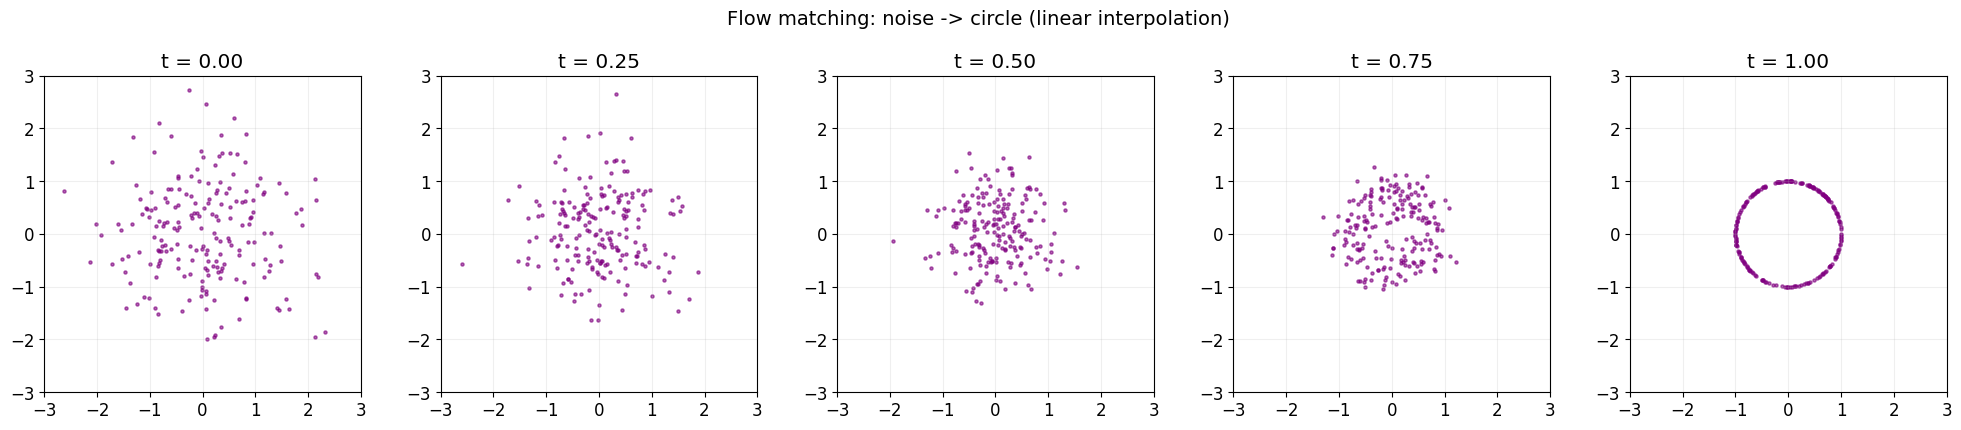

In [28]:
# Simple flow matching idea:
# Velocity field that takes noise at t=0 to target at t=1
# For a linear path: x(t) = (1-t)*x0 + t*x1
# Velocity: dx/dt = x1 - x0 (constant!)

np.random.seed(42)
n_particles = 200

# Source: random noise
x0_particles = np.random.randn(n_particles, 2)

# Target: points on a circle
angles = np.random.uniform(0, 2*np.pi, n_particles)
x1_particles = np.stack([np.cos(angles), np.sin(angles)], axis=1)

# Compute the straight-line velocity for each particle
velocities = x1_particles - x0_particles

# Trace each particle
n_time_steps = 50
t_values = np.linspace(0, 1, n_time_steps)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for idx, t in enumerate([0.0, 0.25, 0.5, 0.75, 1.0]):
    x_t = (1 - t) * x0_particles + t * x1_particles
    axes[idx].scatter(x_t[:, 0], x_t[:, 1], s=5, alpha=0.6, c='purple')
    axes[idx].set_xlim(-3, 3); axes[idx].set_ylim(-3, 3)
    axes[idx].set_title(f't = {t:.2f}')
    axes[idx].set_aspect('equal')
    axes[idx].grid(True, alpha=0.2)

plt.suptitle('Flow matching: noise -> circle (linear interpolation)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

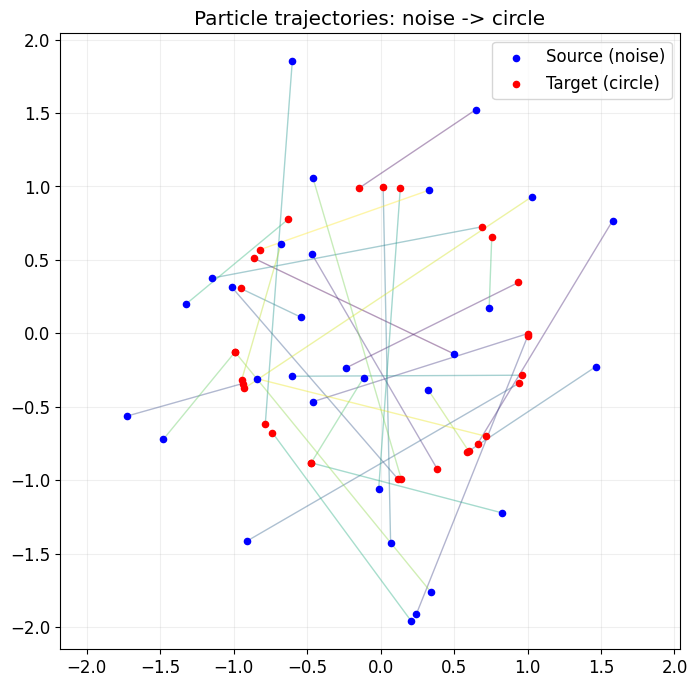

In [29]:
# Show individual particle trajectories
plt.figure(figsize=(8, 8))

# Draw trajectories for a subset of particles
n_show = 30
colors = plt.cm.viridis(np.linspace(0, 1, n_show))

for i in range(n_show):
    # Straight line from source to target
    traj_x = np.linspace(x0_particles[i, 0], x1_particles[i, 0], 50)
    traj_y = np.linspace(x0_particles[i, 1], x1_particles[i, 1], 50)
    plt.plot(traj_x, traj_y, '-', color=colors[i], alpha=0.4, linewidth=1)
    plt.scatter(x0_particles[i, 0], x0_particles[i, 1], c='blue', s=20, zorder=5)
    plt.scatter(x1_particles[i, 0], x1_particles[i, 1], c='red', s=20, zorder=5)

plt.scatter([], [], c='blue', s=20, label='Source (noise)')
plt.scatter([], [], c='red', s=20, label='Target (circle)')
plt.title('Particle trajectories: noise -> circle')
plt.legend()
plt.axis('equal')
plt.grid(True, alpha=0.2)
plt.show()

### 8.5 The field a network actually learns: the *marginal* velocity

A network $v_\theta(x, t)$ sees only the point $x_t$, not which pair $(x_0, x_1)$ produced it. Trained with squared error, it learns the **average** velocity of all pairs passing through that point (MSE regression gives conditional means, 0b §6):

$$v^*(x, t) = \mathbb{E}\,[\,x_1 - x_0 \mid x_t = x\,]$$

For this toy problem we can compute $v^*$ directly. Given $x_1$, the point $x_t$ is Gaussian, $x_t \mid x_1 \sim \mathcal{N}(t\,x_1, (1-t)^2 I)$. Bayes' rule therefore weights each candidate target by how likely it is to have produced $x_t$, and since $x_1 - x_0 = (x_1 - x_t)/(1-t)$:

$$v^*(x, t) = \frac{\mathbb{E}[x_1 \mid x_t = x] - x}{1 - t}$$

We approximate $\mathbb{E}[x_1 \mid x_t]$ with a large reference set of circle points and integrate $v^*$ with Euler.

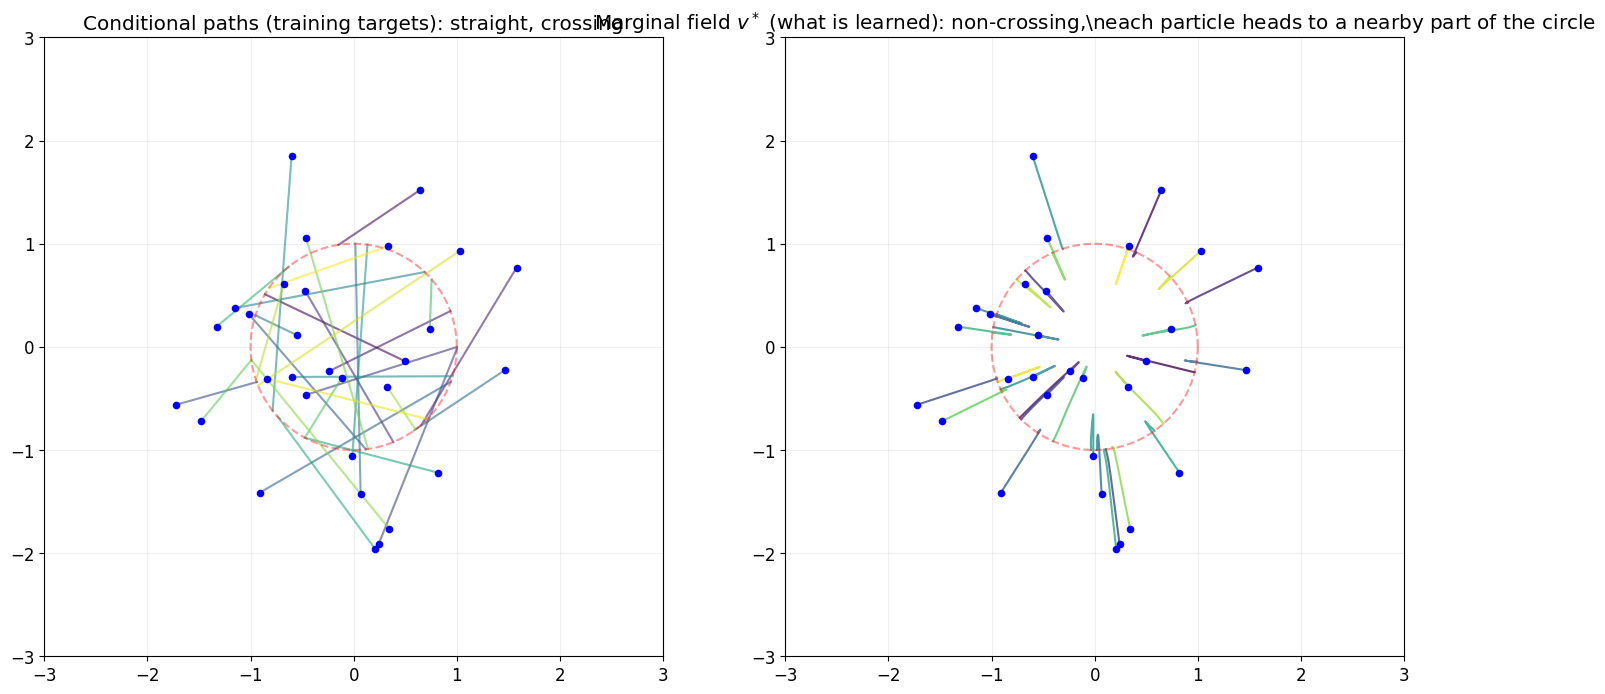

In [30]:
torch.manual_seed(0)
M = 4000
ang = torch.rand(M, dtype=torch.float64) * 2 * np.pi
ref_targets = torch.stack([torch.cos(ang), torch.sin(ang)], 1)          # samples from the target (circle)

def marginal_velocity(x, t):
    # v*(x,t) = (E[x1 | x_t = x] - x) / (1 - t), with E[x1|x_t] from Bayes over the reference targets.
    logw = -0.5 * torch.cdist(x, t * ref_targets) ** 2 / (1 - t) ** 2   # log N(x; t*x1, (1-t)^2 I) + const
    x1_hat = torch.softmax(logw, dim=1) @ ref_targets
    return (x1_hat - x) / (1 - t)

x_start = torch.tensor(x0_particles[:n_show], dtype=torch.float64)
n_steps = 200
xs, path = x_start.clone(), [x_start.clone()]
for i in range(n_steps):
    xs = xs + (1 / n_steps) * marginal_velocity(xs, i / n_steps)
    path.append(xs.clone())
path = torch.stack(path).numpy()

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for i in range(n_show):
    axes[0].plot([x0_particles[i, 0], x1_particles[i, 0]], [x0_particles[i, 1], x1_particles[i, 1]],
                 '-', color=colors[i], alpha=0.6)
    axes[1].plot(path[:, i, 0], path[:, i, 1], '-', color=colors[i], alpha=0.8)
theta = np.linspace(0, 2 * np.pi, 200)
for ax, title in zip(axes, ['Conditional paths (training targets): straight, crossing',
                            'Marginal field $v^*$ (what is learned): non-crossing,\\neach particle heads to a nearby part of the circle']):
    ax.plot(np.cos(theta), np.sin(theta), 'r--', alpha=0.4)
    ax.scatter(x0_particles[:n_show, 0], x0_particles[:n_show, 1], c='blue', s=20, zorder=5)
    ax.set_title(title); ax.set_aspect('equal'); ax.grid(alpha=0.2)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
plt.tight_layout(); plt.show()

Key points (3b covers each one in depth):

- Every particle still ends on the circle: the marginal field transports the noise distribution to the target distribution. That is the flow-matching theorem.
- The paths are **curved** and the pairing between start and end points is **not** the random pairing used in training. Each particle goes to a *nearby* part of the circle.
- Early on ($t \approx 0$) $v^*$ points toward the **mean** of the targets (here the centre), since nothing is known yet. That is why one or two Euler steps produce blurry, averaged samples.
- Because we used a finite reference set, $v^*$ here is exact for *those 4000 points*. As $t \to 1$ every particle snaps onto one of them, i.e. the exact solution memorises its training set. A neural network generalises precisely because it does **not** fit $v^*$ perfectly.

### 8.6 PyTorch ODE solving

In practice, flow matching implementations use ODE solvers on PyTorch tensors. Here's a minimal version. The `ring_velocity` field below is hand-made for illustration (it is *not* a flow-matching field): it pulls each point radially toward the unit circle at a rate that blows up as $t \to 1$, which is why we stop at $t = 0.95$.

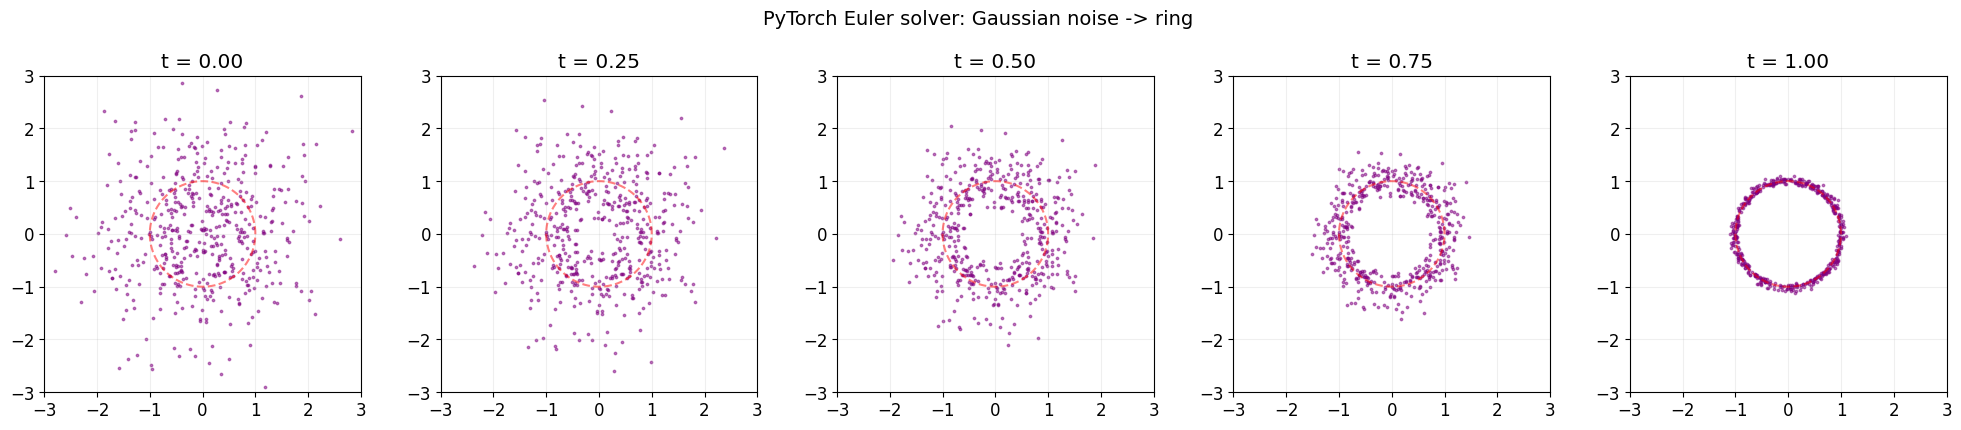

In [31]:
def euler_solve_torch(v_fn, x0, t_start=0.0, t_end=1.0, n_steps=100):
    """Euler ODE solver for PyTorch tensors.
    
    v_fn: function(x, t) -> velocity, where x is (batch, dim) and t is a scalar
    x0: (batch, dim) initial conditions
    """
    dt = (t_end - t_start) / n_steps
    x = x0.clone()
    t = t_start
    
    trajectory = [x.clone()]
    for _ in range(n_steps):
        x = x + dt * v_fn(x, t)
        t += dt
        trajectory.append(x.clone())
    
    return x, trajectory

# Example: transport Gaussian noise to a ring using a known velocity field
def ring_velocity(x, t):
    """Velocity field that moves points toward a unit ring.
    At each time t, the target is a unit ring. We use a simple
    linear interpolation velocity."""
    # Current radius
    r = torch.norm(x, dim=1, keepdim=True).clamp(min=1e-6)
    # Direction (radial unit vector)
    direction = x / r
    # We want r -> 1 as t -> 1
    # Simple approach: velocity = (target - current) / (1 - t + eps)
    target_r = 1.0
    v_radial = (target_r - r) / (1.0 - t + 0.01)
    return v_radial * direction

# Solve
torch.manual_seed(42)
x0 = torch.randn(500, 2)
x_final, trajectory = euler_solve_torch(ring_velocity, x0, t_start=0.0, t_end=0.95, n_steps=100)

# Visualize snapshots
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
snap_indices = [0, 25, 50, 75, 100]
for ax, idx in zip(axes, snap_indices):
    pts = trajectory[idx].numpy()
    ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.5, c='purple')
    # Draw target ring
    theta = np.linspace(0, 2*np.pi, 100)
    ax.plot(np.cos(theta), np.sin(theta), 'r--', alpha=0.5)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
    ax.set_title(f't = {idx/100:.2f}')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

plt.suptitle('PyTorch Euler solver: Gaussian noise -> ring', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---
## Summary: What connects to diffusion models

| Concept | Where it appears in diffusion |
|---|---|
| **Gradients / autograd (VJPs)** | Training via backprop; score $\nabla_x \log p(x)$ and energy gradients $\nabla_x E$ in one backward pass |
| **Vector fields** | Score field, velocity field in flow matching |
| **Divergence** | Continuity equation; exact log-likelihood of flows via $\frac{d}{dt}\log p = -\nabla\cdot v$ |
| **Curl / symmetric Jacobian** | True scores are conservative; EBMs (notebook 7) enforce it, $\epsilon$-networks only approximate it |
| **Jacobians** | Change of variables in normalizing flows; Hutchinson trace estimates for CNF likelihoods |
| **Monte Carlo integration** | Training loss estimation (random timesteps, random noise) |
| **ODE solving** | Sampling in flow matching, DDIM, probability-flow ODE (0c, 3b) |
| **Conditional vs. marginal velocity** | Straight training paths, curved learned trajectories (notebook 4, 3b) |

In the next notebook (0b), we'll build on these tools to understand probability distributions, score functions, and Langevin dynamics, the direct probabilistic foundations of diffusion models.